In [1]:
import os
os.environ.update(dict.fromkeys(['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS'], '1'))    # A BUSCA RODA EM 8 PROCESSOS, UM THREAD CADA

from scipy.spatial.transform import Rotation
from scipy.interpolate import CubicSpline
from scipy.optimize import least_squares
from scipy import signal
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import json, math, datetime, glob, subprocess, time as clock
pd.set_option('display.max_columns', None)

# IMPORTANDO DADOS
- `Dataset/data.csv`, gerado pelo `Dataset/Format.ipynb`: o Kernel-120 nos eixos crus e em SI (`target_`) e a Seatex MRU 5 de referência (`ref_`) no mesmo instante, 13 s parado, 150 s de balanço em roll e 66 s parado
- Os sensores do Kernel são a entrada do filtro, como no firmware; os ângulos e o heave da Seatex são o rótulo; quaternion, acelerômetro e giro da Seatex só entram na calibração e na validação
- `target_roll`, `target_pitch` e `target_yaw` são o AHRS interno do próprio Kernel, só para comparação

In [2]:
DATASET = 'Dataset/data.csv'
RAW     = '../Analysis/Calibration_OLD/Pendulum_Compare_MRU/Format/files'    # ENSAIOS BRUTOS: SÓ A VALIDAÇÃO INDEPENDENTE OS LÊ
G0      = 9.80665                                                           # m/s² POR g
SENSORS = ['ax', 'ay', 'az', 'wx', 'wy', 'wz']
ANGLES  = ['pitch', 'roll', 'yaw']
LABELS  = ANGLES + ['heave']
REF     = LABELS + [f'ref_{var}' for var in ['q0', 'q1', 'q2', 'q3', 'ax', 'ay', 'az', 'wx', 'wy', 'wz']]

df     = pd.read_csv(DATASET).rename(columns={f'target_{var}': var for var in SENSORS} | {f'ref_{var}': var for var in LABELS})
dt     = float(np.median(np.diff(df.time)))
time   = df.time.to_numpy()
static = df.static.to_numpy()
moving = ~static

print(f'{len(df)} amostras a {1/dt:.0f} Hz | {time[-1]:.0f} s | {static.mean():.0%} em repouso')
df.head(3)

2297 amostras a 10 Hz | 230 s | 34% em repouso


,time,static,ax,ay,az,wx,wy,wz,target_roll,target_pitch,target_yaw,roll,pitch,yaw,heave,ref_q0,ref_q1,ref_q2,ref_q3,ref_ax,ref_ay,ref_az,ref_wx,ref_wy,ref_wz
0,0.0,True,0.246971,-0.410624,9.778721,-0.07912,0.05244,-0.14963,-1.387,-2.473,3.030,-92.188909,0.500249,-4.101805,0.5481,-0.6933,0.7198,-0.02880,0.02168,0.1148,9.779,0.3699,-0.029301,0.022271,0.004696
1,0.1,True,0.268271,-0.458598,9.757764,0.29277,-0.33624,0.30280,-1.388,-2.481,3.033,-92.188909,0.499848,-4.102951,0.5439,-0.6933,0.7198,-0.02881,0.02169,0.1137,9.777,0.3691,-0.017424,0.014146,-0.017097
2,0.2,True,0.252335,-0.420372,9.739690,0.07205,-0.14049,-0.35499,-1.389,-2.472,3.046,-92.188909,0.499161,-4.104670,0.5398,-0.6932,0.7198,-0.02882,0.02170,0.1148,9.779,0.3693,-0.041259,0.018254,-0.003837


# RUÍDO DOS SENSORES
- No repouso o desvio de Allan separa os ruídos (IEEE Std 952-1997): inclinação $-1/2$ é ruído branco e $\sigma_A(1\,\mathrm{s})$ é a densidade, o ARW do giro e o VRW do acelerômetro do datasheet

$$\sigma_A^2(\tau) = \frac{1}{2\tau^2}\left\langle\left(\theta_{k+2m} - 2\,\theta_{k+m} + \theta_k\right)^2\right\rangle, \qquad \theta_k = \sum_{j \le k} x_j\,\Delta t, \quad \tau = m\,\Delta t$$

- A variância por amostra do giro parado é o $R$ dos osciladores e do ZARU; a do acelerômetro sobre $g^2$ é o $R$ do acelerômetro parado; a norma média do acelerômetro parado é a gravidade local $g$
- Ruído branco de densidade $N$ amostrado a $f$ tem variância $N^2 f$ por amostra. Com o ARW do datasheet, o $\sigma$ medido por amostra diz a que taxa o Kernel amostrou: dá a taxa interna dele, 2 kHz. Cada linha é o valor **instantâneo**, não a média dos 100 ms (ICD do Kernel, §5.3.6)

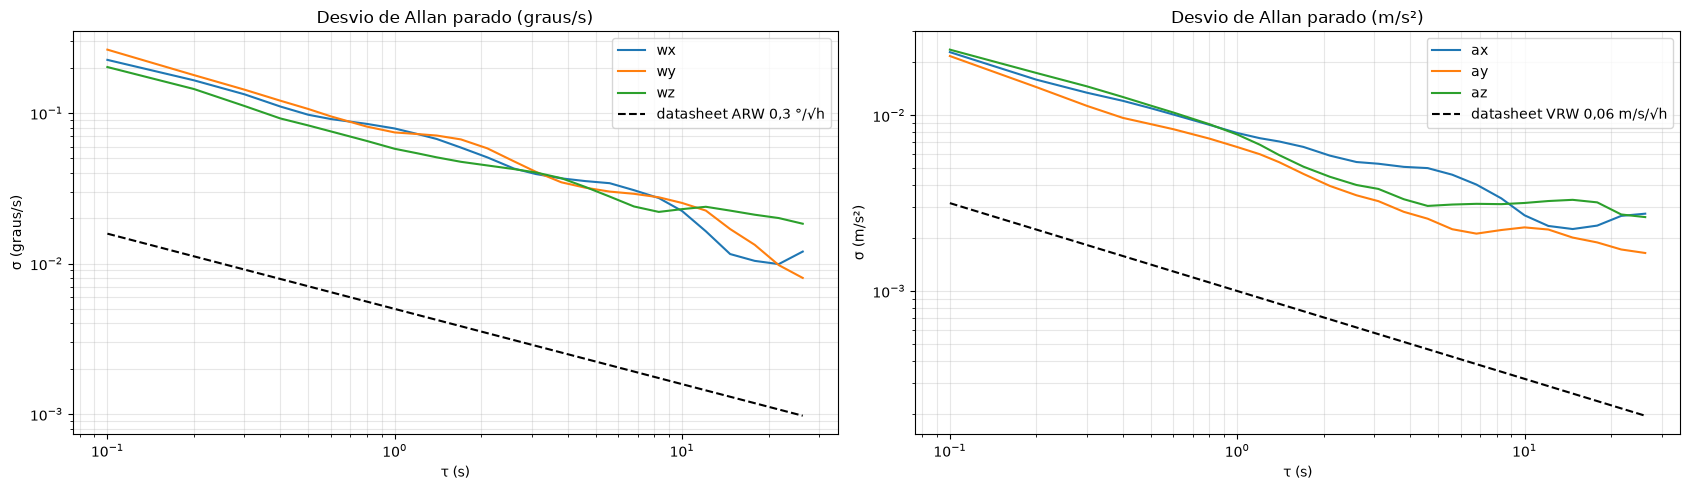

g local 9.7876 m/s² | por amostra: giro 0.229 °/s, acelerômetro 0.0230 m/s² | o σ do giro é o do ARW amostrado a 2101 Hz


In [3]:
ARW = 0.3/60     # °/√s, DATASHEET DO KERNEL-120: 0,3 °/√h
VRW = 0.06/60    # m/s/√s: 0,06 m/s/√h


# DESVIO DE ALLAN SOBREPOSTO DE UM SINAL AMOSTRADO A dt
def allan(values, dt):
    theta  = np.cumsum(values) * dt
    counts = np.unique(np.logspace(0, np.log10(len(values)//3), 30).astype(int))
    sigma  = [np.sqrt(np.mean((theta[2*m:] - 2*theta[m:-m] + theta[:-2*m])**2) / (2*(m*dt)**2)) for m in counts]
    return counts*dt, np.array(sigma)


still  = df[static]
panels = [(['wx', 'wy', 'wz'], 'graus/s', ARW, 'ARW 0,3 °/√h'), (['ax', 'ay', 'az'], 'm/s²', VRW, 'VRW 0,06 m/s/√h')]
plt.figure(figsize=(17, 5))

for i, (cols, unit, density, label) in enumerate(panels):
    plt.subplot(1, 2, i + 1)

    for col in cols:
        tau, sigma = allan(still[col].to_numpy(), dt)
        plt.loglog(tau, sigma, label=col)

    plt.loglog(tau, density/np.sqrt(tau), 'k--', label=f'datasheet {label}')
    plt.title(f'Desvio de Allan parado ({unit})'); plt.xlabel('τ (s)'); plt.ylabel(f'σ ({unit})'); plt.grid(which='both', alpha=.3); plt.legend()

plt.tight_layout()
plt.show()

G           = float(np.linalg.norm(still[['ax', 'ay', 'az']], axis=1).mean())
RATE_NOISE  = float(np.log10(np.radians(still[['wx', 'wy', 'wz']]).var().mean()))
STILL_NOISE = float(np.log10((still[['ax', 'ay', 'az']].var() / G**2).mean()))
GYRO_SIGMA  = float(np.degrees(10**(RATE_NOISE/2)))
ACCEL_SIGMA = float(G * 10**(STILL_NOISE/2))
print(f'g local {G:.4f} m/s² | por amostra: giro {GYRO_SIGMA:.3f} °/s, acelerômetro {ACCEL_SIGMA:.4f} m/s² | o σ do giro é o do ARW amostrado a {(GYRO_SIGMA/ARW)**2:.0f} Hz')

# CALIBRAÇÃO
- Quatro passos ligam o Kernel à referência, todos com o filtro de fora: a defasagem entre as duas gravações, a montagem e o braço de alavanca pelo balanço, o nivelamento pelo repouso e a atitude de referência parada
- É a calibração de instalação de um MRU a bordo (ângulos de montagem, braços de alavanca, nivelamento no cais); o filtro em si nunca vê a referência

### DEFASAGEM
- O passa-baixa de vibração da Seatex, de segunda ordem e 10 Hz, age sobre as taxas e as acelerações, não sobre os ângulos (manual da MRU 5, §18.4.4.1): o giro dela sai uns 22 ms atrás dos próprios ângulos. Por isso o atraso é medido entre a taxa do Kernel e a taxa dos ângulos da Seatex, a derivada do quaternion
- Pico da correlação cruzada das normas, refinado pela parábola nos três pontos em volta: a 10 Hz o atraso é uma fração de amostra
- A referência é deslocada por interpolação; a entrada do filtro fica como foi gravada, que é o que o firmware recebe

In [4]:
# ATRASO DA IMU EM TESTE CONTRA OS ÂNGULOS DA REFERÊNCIA, COM RESOLUÇÃO MENOR QUE UMA AMOSTRA
class Phaser:
    def __init__(self, columns):
        self.columns = columns

    def get(self, df):
        time   = df.time.to_numpy()
        R      = Rotation.from_quat(df[['ref_q1', 'ref_q2', 'ref_q3', 'ref_q0']].to_numpy())
        spin   = np.degrees(np.linalg.norm((R[:-1].inv() * R[1:]).as_rotvec(), axis=1) / np.diff(time))
        ref    = np.interp(time, (time[:-1] + time[1:])/2, spin)
        target = np.linalg.norm(df[['wx', 'wy', 'wz']], axis=1)
        corr   = np.correlate(ref - ref.mean(), target - target.mean(), mode='full')
        k      = int(np.argmax(corr))
        peak   = (corr[k-1] - corr[k+1]) / (2*(corr[k-1] - 2*corr[k] + corr[k+1]))    # VÉRTICE DA PARÁBOLA PELOS TRÊS PONTOS DO PICO
        return -(k - len(time) + 1 + peak) * float(np.median(np.diff(time)))

    def set(self, df, delay):
        out = df.copy()

        for col in self.columns:
            out[col] = np.interp(df.time - delay, df.time, df[col])

        quat = out[['ref_q0', 'ref_q1', 'ref_q2', 'ref_q3']]
        out[quat.columns] = quat.to_numpy() / np.linalg.norm(quat, axis=1)[:, None]
        return out


phaser = Phaser(REF)
delay  = phaser.get(df)
df     = phaser.set(df, delay)
print(f'o Kernel chega {1000*delay:.1f} ms depois dos ângulos da Seatex')

o Kernel chega 17.7 ms depois dos ângulos da Seatex


### MONTAGEM E BRAÇO DE ALAVANCA
No pêndulo o pivô não acelera, então o acelerômetro de um ponto rígido a $r$ do pivô mede (WO 2011/034435, Eq. 2)

$$f = R^\top \begin{bmatrix}0\\0\\-g\end{bmatrix} + \omega\times(\omega\times r) + \dot\omega\times r$$

- Com a atitude $R$ da Seatex, mínimos quadrados acham a rotação de montagem (eixos crus do Kernel → referencial da Seatex, Euler `xyz`) e o braço $r$ do Kernel; a mesma conta com os sensores da Seatex dá o braço dela, que vira o ponto de medida `point` do heave
- Só o balanço entra, partindo de oito orientações: a montagem pode estar em qualquer quadrante
- O resíduo diz se o modelo de corpo rígido fecha

In [5]:
STARTS = [(0, 0, 0), (90, 0, 0), (-90, 0, 0), (180, 0, 0), (0, 90, 0), (0, -90, 0), (90, 0, 90), (90, 0, -90)]


# MONTAGEM E BRAÇO DE ALAVANCA DE UM SENSOR NO PÊNDULO RÍGIDO, PELA ATITUDE DA REFERÊNCIA
def calibrate(df, accCols, gyroCols, g, starts=STARTS):
    time  = df.time.to_numpy()
    step  = np.diff(time) < 3*np.median(np.diff(time))
    keep  = np.r_[False, step] & np.r_[step, False]    # A DERIVADA CENTRAL NÃO ATRAVESSA BURACO
    R     = Rotation.from_quat(df[['ref_q1', 'ref_q2', 'ref_q3', 'ref_q0']].to_numpy()).as_matrix()
    accel = df[accCols].to_numpy()
    gyro  = np.radians(df[gyroCols].to_numpy())

    def residual(p):
        M     = Rotation.from_euler('xyz', p[:3], degrees=True).as_matrix()
        w     = gyro @ M
        alpha = np.gradient(w, time, axis=0)
        model = np.einsum('nji,j->ni', R, [0, 0, -g]) + np.cross(w, np.cross(w, p[3:])) + np.cross(alpha, p[3:])
        return (accel @ M - model)[keep].ravel()

    best = min((least_squares(residual, np.r_[start, 0, -1.9, 0]) for start in starts), key=lambda fit: fit.cost)
    return best.x[:3], best.x[3:], float(np.sqrt(np.mean(best.fun**2)))


gRef = float(np.linalg.norm(still[['ref_ax', 'ref_ay', 'ref_az']], axis=1).mean())

mount, lever, fitKernel = calibrate(df[moving], ['ax', 'ay', 'az'], ['wx', 'wy', 'wz'], G)
_, point, fitSeatex     = calibrate(df[moving], ['ref_ax', 'ref_ay', 'ref_az'], ['ref_wx', 'ref_wy', 'ref_wz'], gRef, [(0, 0, 0)])

calibration = pd.DataFrame([[*mount, *lever, fitKernel], [0, 0, 0, *point, fitSeatex]], index=['Kernel', 'Seatex'], columns=['align_x', 'align_y', 'align_z', 'r_x', 'r_y', 'r_z', 'resíduo (m/s²)'])
calibration

,align_x,align_y,align_z,r_x,r_y,r_z,resíduo (m/s²)
Kernel,90.451914,0.551246,7.553407,0.041806,-1.910245,0.059287,0.084251
Seatex,0.000000,0.000000,0.000000,0.067793,-1.974717,-0.171894,0.054301


### NIVELAMENTO
- Parado, a força específica é só a gravidade: o acelerômetro do Kernel, já nos eixos da referência, tem de apontar para onde aponta o acelerômetro da Seatex. A menor rotação que fecha esse ângulo só mexe na inclinação e completa a montagem
- O balanço sozinho deixa uns 0,2° de inclinação em aberto: num balanço em torno de um eixo só, bias do acelerômetro e montagem quase não se separam
- É o nivelamento no cais de uma instalação a bordo

In [6]:
# MONTAGEM CUJA VERTICAL DO ACELERÔMETRO PARADO COINCIDE COM A DO ACELERÔMETRO DA REFERÊNCIA
def level(df, mount):
    M    = Rotation.from_euler('xyz', mount, degrees=True).as_matrix()
    up   = (df[['ax', 'ay', 'az']].to_numpy() @ M).mean(axis=0)
    ref  = df[['ref_ax', 'ref_ay', 'ref_az']].to_numpy().mean(axis=0)
    axis = np.cross(up/np.linalg.norm(up), ref/np.linalg.norm(ref))
    tilt = Rotation.from_rotvec(axis/np.linalg.norm(axis) * np.arcsin(np.linalg.norm(axis))).as_matrix()
    return Rotation.from_matrix(M @ tilt.T).as_euler('xyz', degrees=True)


align = level(df[static], mount)
pd.DataFrame([mount, align], index=['balanço', 'nivelada'], columns=['align_x', 'align_y', 'align_z'])

,align_x,align_y,align_z
balanço,90.451914,0.551246,7.553407
nivelada,90.529222,0.369146,7.544073


### ATITUDE DE REFERÊNCIA PARADA
- Parada, a atitude verdadeira é a que a gravidade dá no acelerômetro da referência: $\mathrm{roll} = \operatorname{atan2}(-u_y, -u_z)$ e $\mathrm{pitch} = \operatorname{atan2}(u_x, \sqrt{u_y^2 + u_z^2})$, com $u = f/\lVert f\rVert$
- O pêndulo pendura sempre igual, e a gravidade medida pela Seatex confirma: no trecho antes e no trecho depois do balanço o pitch dela fica igual a 0,01°, mas o pitch que ela informa anda 0,28° — o filtro interno dela carrega o balanço por minutos. Em repouso, o rótulo de roll e pitch passa a ser o da gravidade

In [7]:
# ROLL E PITCH QUE A GRAVIDADE DÁ NO ACELERÔMETRO DA REFERÊNCIA
def gravity(df):
    u = df[['ref_ax', 'ref_ay', 'ref_az']].to_numpy()
    u = u / np.linalg.norm(u, axis=1)[:, None]
    return {'roll': np.degrees(np.arctan2(-u[:, 1], -u[:, 2])), 'pitch': np.degrees(np.arctan2(u[:, 0], np.hypot(u[:, 1], u[:, 2])))}


truth    = gravity(df)
block    = np.cumsum(np.r_[0, np.diff(static.astype(int)) != 0])    # NÚMERO DE CADA TRECHO CONTÍNUO
segments = pd.DataFrame({'início (s)': time, 'roll Seatex': df.roll, 'roll gravidade': truth['roll'], 'pitch Seatex': df.pitch, 'pitch gravidade': truth['pitch']})[static].groupby(block[static]).agg({'início (s)': 'min', 'roll Seatex': 'mean', 'roll gravidade': 'mean', 'pitch Seatex': 'mean', 'pitch gravidade': 'mean'})

for name in ['roll', 'pitch']:
    df[name] = np.where(static, truth[name], df[name])

segments.round(3)

,início (s),roll Seatex,roll gravidade,pitch Seatex,pitch gravidade
0,0.0,-92.168,-92.163,0.489,0.672
2,164.0,-92.139,-92.153,0.766,0.684


# FILTRO DE KALMAN

Três blocos encadeados, todos causais e amostra a amostra, na mesma ordem do `Hardware/index.h`.

**1. MEKF de atitude.** Estado nominal: quaternion $q$ do corpo para a navegação, com $z$ para baixo como a referência (parada, a força específica é $[0,0,-g]$), e bias $b$ do giro; o erro é multiplicativo, $q_{real} = q \otimes \delta q(\delta\theta)$, e a covariância só carrega $\delta x = [\,\delta\theta,\ \delta b\,] \in \mathbb{R}^6$ (Lefferts, Markley e Shuster 1982; Markley 2003; Solà 2017).
- Propagação com a exponencial exata, $q \leftarrow q \otimes \exp\big(\tfrac{1}{2}(\tilde\omega - b)\Delta t\big)$, onde $\tilde\omega_k = \omega_k - \phi\,(\omega_k - \omega_{k-1})$ põe a taxa no instante certo do passo (`gyroPhase`)
- Transição do erro $\Phi = \begin{bmatrix} e^{-[\omega\times]\Delta t} & -\left(I\Delta t - [\omega\times]\tfrac{\Delta t^2}{2} + [\omega\times]^2\tfrac{\Delta t^3}{6}\right) \\ 0 & I \end{bmatrix}$ e ruído discreto de Farrell, $Q_{\theta\theta} = \sigma_g^2\Delta t + \sigma_b^2\Delta t^3/3$, $Q_{\theta b} = -\sigma_b^2\Delta t^2/2$, $Q_{bb} = \sigma_b^2\Delta t$
- **Braço de alavanca** (WO 2011/034435, Eq. 2 invertida): o acelerômetro só vira gravidade depois de tirar $f_c = f - \omega\times(\omega\times r) - \alpha\times r$, com $\alpha_k = (\omega_k - \omega_{k-m})/(t_k - t_{k-m})$ numa janela de 0,05 s — um passo a 10 Hz, cinco a 100 Hz, onde a diferença de um passo só multiplicaria o ruído do giro por $1/\Delta t$
- **Acelerômetro:** $z = f_c/\lVert f_c\rVert$, $h = R^\top[0,0,-1]$, $H = [\,[h\times]\ \ 0\,]$. Em movimento $R = \sigma_a^2\big(1 + K\,((\lVert f_c\rVert - g)/g)^2\big)I$ cobre o que o modelo não explica; **parado** não há rotação, o braço sai ($f_c = f$) e $R$ é o ruído do próprio acelerômetro, $\sigma_f^2/g^2$
- A proa não é observável sem magnetômetro: $P_0 = C^\top \mathrm{diag}(\sigma_{tilt}^2, \sigma_{tilt}^2, \sigma_{yaw}^2)\,C$ com $\sigma_{yaw}$ pequeno, senão a correção de inclinação vaza para o yaw
- **ZARU:** em repouso contínuo por 1 s ($|\lVert f\rVert - g| < 0{,}2$ m/s² e $\lVert\omega\rVert < 1$ °/s) a taxa verdadeira é zero, $z = \omega$, $H = [\,0\ \ I\,]$, com a variância do giro parado (Skog et al. 2010) — o pêndulo para um instante em cada inversão, por isso a janela
- **Proa intocada:** nenhuma das duas medidas observa a proa, então a coluna de atitude do ganho perde a componente na vertical da navegação, $K_\theta \leftarrow (I - u u^\top)K_\theta$ com $u = R^\top e_z$; sem isso as correlações de $P$ giram o yaw
- **Joseph:** $P = (I-KH)P(I-KH)^\top + KRK^\top$, que continua certa para esse ganho restrito
- **Integridade:** amostra isolada cuja aceleração do CG na navegação salta mais que `spike` em relação à anterior é pico (o Kernel tem picos de até 3 m/s² que a Seatex não vê): não corrige a atitude e o heave segura o valor anterior

**2. Osciladores harmônicos (WO 2011/034435).** Um por eixo do corpo, estado $x = [\theta,\ \dot\theta]$ medido pela taxa:

$$\dot x_1 = x_2, \quad \dot x_2 = x_3 = -D\,x_2 - \Omega^2 x_1 \;\;(\text{Eq. 9}), \qquad A = \begin{bmatrix} 1 & \Delta t \\ -\Omega^2\Delta t & 1 - D\Delta t \end{bmatrix} \;\;(\text{Eq. 11.2}), \qquad H_3 = [\,0\ \ 1\,] \;\;(\text{Eq. 12.5})$$

- $\Omega^2$ e $D$ saem de mínimos quadrados recursivos de $\alpha_k = -\Omega^2 x_1 - D x_2$ (Eq. 18), com esquecimento $e^{-\Delta t/30\,\mathrm{s}}$ e um peso pequeno no período e no amortecimento iniciais da patente (9 s e 0,05): sem isso o primeiro passo, de posto 1, joga $\Omega^2$ para longe. O período é $T = 2\pi/\Omega$ (Eq. 18.4)
- Saídas filtradas: taxa $\hat\omega = x_2$, aceleração angular $\hat\alpha = x_3$ e a aceleração no ponto de medida $a_m = C\,(f_c + \hat\alpha\times m + \hat\omega\times(\hat\omega\times m)) + g\,e_z$ (Eq. 2)

**3. Heave do MRU-5 (EP 2 092 402).** Aceleração vertical do CG $a_{cg} = (C f_c)_z + g$, positiva para baixo, integrada duas vezes com um passa-alta de segunda ordem em cada etapa, $\omega_c = 2\pi/(10\,T_h)$:

$$G_{GP} = \frac{s^2}{s^2 + 2\varepsilon\omega_c s + \omega_c^2}, \qquad G_{HS} = \frac{s^2 + 4\varepsilon\omega_c s}{s^2 + 2\varepsilon\omega_c s + \omega_c^2}, \qquad v = \frac{G_{GP}}{s}\,a_{cg}, \quad p = \frac{G_{HS}}{s}\,v$$

- O avanço de fase do GP e o atraso do HS se cancelam em primeira ordem: $G_{GP}G_{HS} \approx 1 + O(\omega_c^2/\omega^2)$, o modo *hydrographic survey* que a EP recomenda quando a fase importa
- O ponto de medida $m$ soma o termo geométrico $(C\,m)_z$ passado pelo mesmo $G_{GP}G_{HS}$ (EP [0033]: o heave do ponto é o do CG mais o que a rolagem e a arfagem produzem), $\text{heave} = p + G_{GP}G_{HS}\{(Cm)_z\}$
- A taxa de heave é a derivada exata da posição, $\dot p = v + 2\varepsilon\omega_c y' - \omega_c^2 y$, que é a correção de fase $v_G = 2\varepsilon\omega_c\,p$ da reivindicação 2 da EP
- Cada seção $\ddot z = u - 2\varepsilon\omega_c \dot z - \omega_c^2 z$ é integrada com a entrada linear no passo: $z_{k+1} = z_k + \dot z_k\Delta t + \Delta t^2 (2w_k + w_{k+1})/6$, $\dot z_{k+1} = \dot z_k + \Delta t\,(w_k + w_{k+1})/2$
- O heave do CG só começa a integrar 10 s depois da partida ou de um buraco, quando a inclinação já convergiu

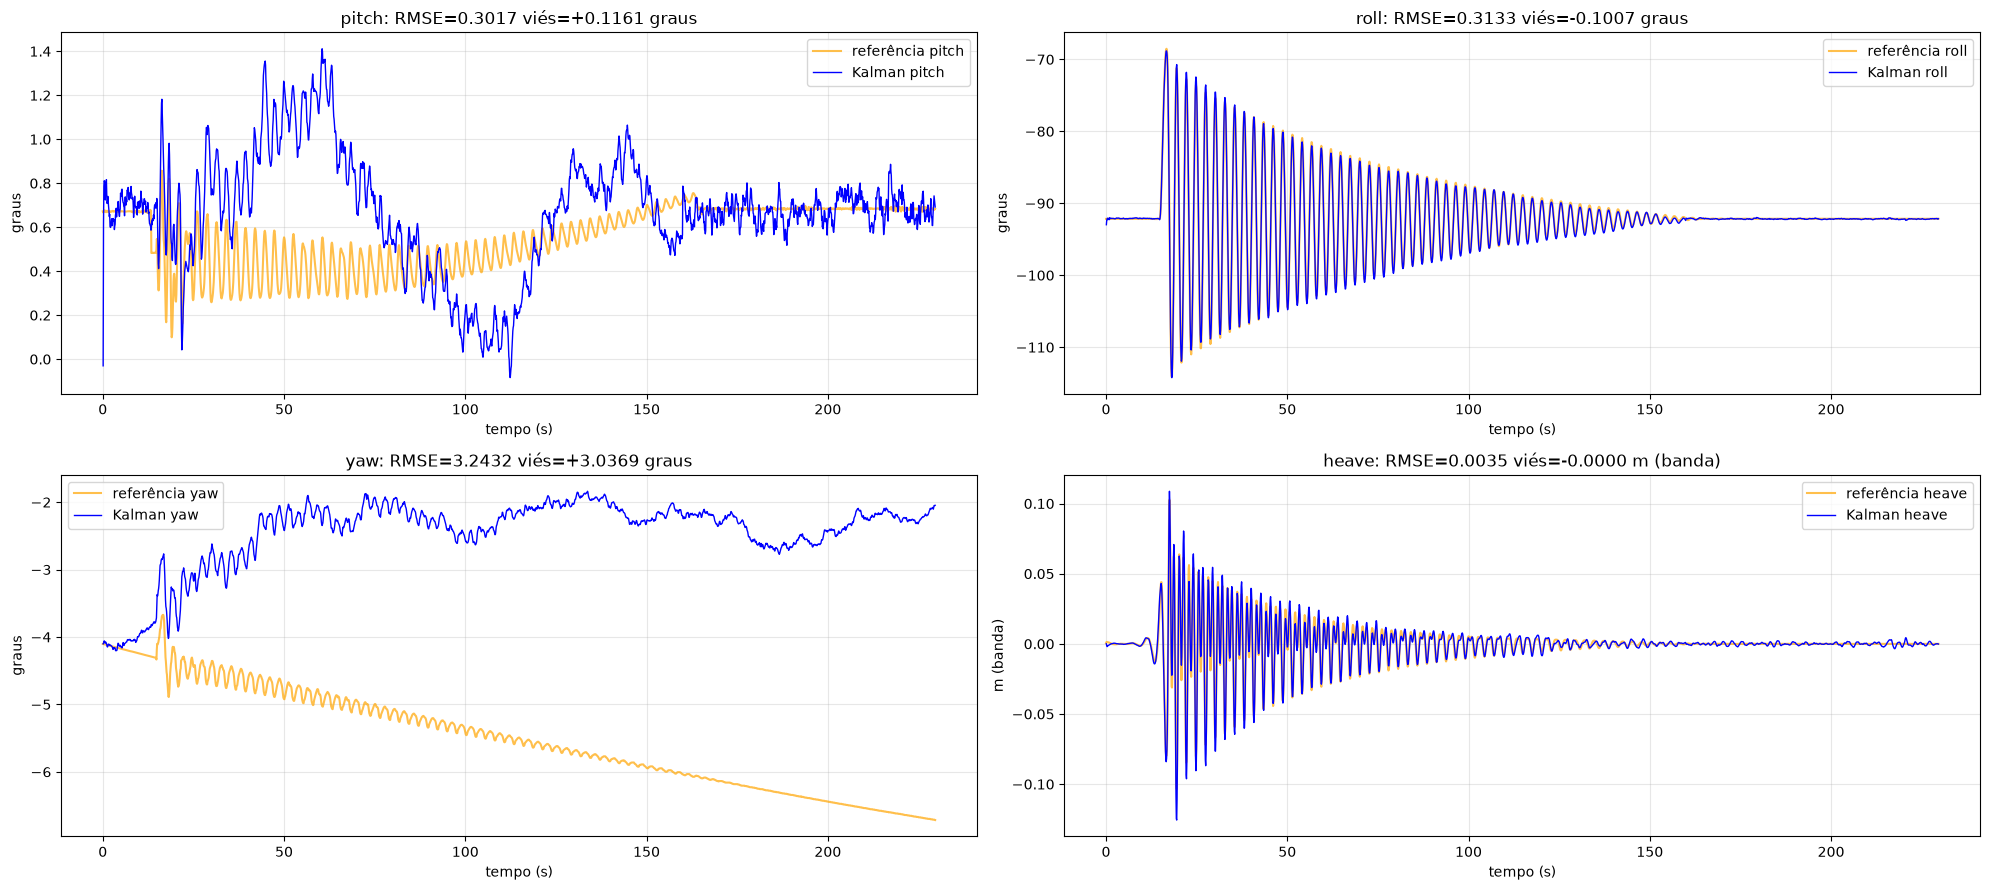

In [8]:
# MEKF DE ATITUDE COM OSCILADORES HARMÔNICOS (WO 2011/034435) E CADEIA DE HEAVE DO MRU-5 (EP 2 092 402)
class KalmanFilter:
    TILT_P0     = 1.0                     # (rad²) INCLINAÇÃO INICIAL DESCONHECIDA: DEIXA O ACELERÔMETRO PUXAR
    YAW_P0      = 1e-4                    # (rad²) A PROA VEM DE FORA: SEM ISSO A CORREÇÃO DE INCLINAÇÃO VAZA PARA O YAW
    BIAS_P0     = 1e-4                    # ((rad/s)²) BIAS INICIAL TÍPICO DE UM MEMS JÁ COMPENSADO
    GAP_FACTOR  = 3.0                     # ACIMA DISSO O INTERVALO É BURACO DE AQUISIÇÃO, NÃO AMOSTRA
    MIN_STEP    = 0.5                     # FRAÇÃO DO PASSO NOMINAL ABAIXO DA QUAL A DIFERENÇA DO GIRO NÃO VIRA DERIVADA
    ALPHA_TIME  = 0.05                    # (s) JANELA DA DERIVADA DO GIRO: A 100 Hz UM PASSO SÓ MULTIPLICA O RUÍDO POR 1/dt
    STILL_ACCEL = 0.20                    # (m/s²) TOLERÂNCIA DE |a|-g NO DETECTOR DE REPOUSO
    STILL_GYRO  = math.radians(1.0)       # (rad/s) TOLERÂNCIA DE |ω| NO DETECTOR DE REPOUSO
    STILL_TIME  = 1.0                     # (s) REPOUSO CONTÍNUO EXIGIDO: O PÊNDULO PARA UM INSTANTE EM CADA INVERSÃO
    ALIGN_TIME  = 10.0                    # (s) O HEAVE DO CG SÓ INTEGRA DEPOIS QUE A INCLINAÇÃO CONVERGIU
    OSC_PERIOD  = 9.0                     # (s) PERÍODO INICIAL DOS OSCILADORES, O DO EXEMPLO DA WO
    OSC_DAMPING = 0.05                    # (1/s) AMORTECIMENTO INICIAL, O DO EXEMPLO DA WO
    OSC_NOISE   = 1.0                     # ((rad/s²)²/Hz) RUÍDO DE PROCESSO DA TAXA NOS OSCILADORES
    OSC_MEMORY  = 30.0                    # (s) MEMÓRIA DOS MÍNIMOS QUADRADOS DE Ω E D (Eq. 18)
    OSC_PRIOR   = 1e-2                    # PESO DOS VALORES INICIAIS NOS MÍNIMOS QUADRADOS: SEM EXCITAÇÃO A ESTIMATIVA FICA NELES
    OMEGA_RANGE = (2*math.pi/30, 2*math.pi/0.5)
    DAMPING_MAX = 2.0
    HEAVE_BAND  = (0.25, 2.5)             # (Hz) BANDA DO MOVIMENTO NO ENSAIO: ABAIXO DELA É TRANSITÓRIO DO FILTRO DA REFERÊNCIA
    OUTPUTS     = ['roll', 'pitch', 'yaw', 'heave', 'heave_rate', 'heave_accel', 'wx', 'wy', 'wz', 'alpha_x', 'alpha_y', 'alpha_z', 'accel_n', 'accel_e', 'accel_d', 'period_x', 'period_y', 'period_z']

    def __init__(self, df, xCols, yCols, params=None):
        self.df     = df.reset_index(drop=True).copy()
        self.xCols  = xCols
        self.yCols  = yCols
        self.params = params or {}

        p = self.params
        self.g            = p.get('g', 9.81)
        self.gyroNoise    = 10 ** p.get('gyroNoise',  -6.0)     # LOG10 DA DENSIDADE DE RUÍDO DO GIRO, (rad/s)²/Hz
        self.biasNoise    = 10 ** p.get('biasNoise', -12.0)     # LOG10 DO RANDOM WALK DO BIAS, (rad/s²)²/Hz
        self.accelNoise   = 10 ** p.get('accelNoise', -2.0)     # LOG10 DA VARIÂNCIA DO VERSOR DO ACELERÔMETRO EM MOVIMENTO
        self.stillNoise   = 10 ** p.get('stillNoise', -5.0)     # LOG10 DA VARIÂNCIA DO VERSOR PARADO: SÓ O RUÍDO DO SENSOR
        self.zuptNoise    = 10 ** p.get('zuptNoise',  -5.0)     # LOG10 DA VARIÂNCIA DO ZARU, (rad/s)²
        self.accelGateK   = 10 ** p.get('accelGateK',  2.0)     # LOG10 DO GANHO QUE INFLA R QUANDO |a| FOGE DE g
        self.rateNoise    = 10 ** p.get('rateNoise',  -4.8)     # LOG10 DA VARIÂNCIA DA TAXA MEDIDA NOS OSCILADORES, (rad/s)²
        self.gyroPhase    = p.get('gyroPhase', 0.5)             # FASE DA TAXA INTEGRADA: 0 RETANGULAR, 0.5 TRAPEZOIDAL
        self.spike        = p.get('spike', 2.0)                 # (m/s²) SALTO ISOLADO DA ACELERAÇÃO DO CG QUE É PICO, NÃO MOVIMENTO
        self.heavePeriod  = p.get('heavePeriod', 10.0)          # (s) Th DA EP: wc = 2π / (10 Th)
        self.heaveDamping = p.get('heaveDamping', 0.7)          # ε DOS FILTROS GP E HS
        self.align        = np.array([p.get('alignX', 0.0), p.get('alignY', 0.0), p.get('alignZ', 0.0)])
        self.lever        = np.array([p.get('leverX', 0.0), p.get('leverY', 0.0), p.get('leverZ', 0.0)])
        self.point        = np.array([p.get('pointX', 0.0), p.get('pointY', 0.0), p.get('pointZ', 0.0)])
        self.yaw0         = p.get('yaw0')
        self.wc           = 2*math.pi / (10*self.heavePeriod)

    def quatMul(self, q1, q2):
        w1, x1, y1, z1 = q1
        w2, x2, y2, z2 = q2
        return np.array([
            w1*w2 - x1*x2 - y1*y2 - z1*z2,
            w1*x2 + x1*w2 + y1*z2 - z1*y2,
            w1*y2 - x1*z2 + y1*w2 + z1*x2,
            w1*z2 + x1*y2 - y1*x2 + z1*w2,
        ])

    # EXPONENCIAL EXATA DO VETOR DE ROTAÇÃO: A 10 Hz O PASSO CHEGA A 7°, ONDE O SENO JÁ NÃO É LINEAR
    def quatFromRotVec(self, rotVec):
        angle = float(np.linalg.norm(rotVec))
        if angle < 1e-12:
            return np.array([1.0, *(rotVec / 2.0)])
        return np.array([math.cos(angle/2), *(rotVec / angle * math.sin(angle/2))])

    # MATRIZ DE ROTAÇÃO CORPO -> NAVEGAÇÃO (CONVENÇÃO DE HAMILTON, v_nav = R @ v_corpo)
    def quatToDCM(self, q):
        w, x, y, z = q
        return np.array([
            [1-2*(y*y+z*z), 2*(x*y-w*z),   2*(x*z+w*y)],
            [2*(x*y+w*z),   1-2*(x*x+z*z), 2*(y*z-w*x)],
            [2*(x*z-w*y),   2*(y*z+w*x),   1-2*(x*x+y*y)],
        ])

    def skew(self, v):
        return np.array([
            [0, -v[2], v[1]],
            [v[2], 0, -v[0]],
            [-v[1], v[0], 0],
        ])

    # NIVELAMENTO PELO ACELERÔMETRO: u = R.T @ [0,0,-1] DÁ ROLAGEM E ARFAGEM; A PROA VEM DE FORA
    def initQuat(self, u, yaw):
        roll  = math.atan2(-u[1], -u[2])
        pitch = math.atan2(u[0], math.hypot(u[1], u[2]))
        cr, sr = math.cos(roll/2), math.sin(roll/2)
        cp, sp = math.cos(pitch/2), math.sin(pitch/2)
        cy, sy = math.cos(math.radians(yaw)/2), math.sin(math.radians(yaw)/2)
        return np.array([cr*cp*cy + sr*sp*sy, sr*cp*cy - cr*sp*sy, cr*sp*cy + sr*cp*sy, cr*cp*sy - sr*sp*cy])

    # INCREMENTO DE ATITUDE E TRANSIÇÃO DO ERRO [dθ, db] NUM PASSO
    def transition(self, w, dt):
        dq = self.quatFromRotVec(w * dt)
        S  = self.skew(w)
        F  = np.eye(6)
        F[:3, :3] = self.quatToDCM(dq).T                                  # exp(-[ω×]dt) EXATO
        F[:3, 3:] = -(np.eye(3)*dt - S*dt**2/2 + S@S*dt**3/6)             # -∫exp(-[ω×]s)ds
        return dq, F

    # PROPAGA ATITUDE E BIAS; dtQ É O TEMPO REAL DECORRIDO, dt O INTEGRADO (LIMITADO EM BURACOS)
    def predict(self, q, b, P, rate, dt, dtQ):
        dq, F = self.transition(rate - b, dt)
        q     = self.quatMul(q, dq)
        q    /= np.linalg.norm(q)

        sg, sb, I = self.gyroNoise, self.biasNoise, np.eye(3)
        Q = np.zeros((6, 6))
        Q[:3, :3] = I * (sg*dtQ + sb*dtQ**3/3)
        Q[:3, 3:] = Q[3:, :3] = I * (-sb*dtQ**2/2)            # TERMO CRUZADO: É ELE QUE FAZ O BIAS CONVERGIR
        Q[3:, 3:] = I * (sb*dtQ)
        return q, b, F @ P @ F.T + Q

    # CORREÇÃO MULTIPLICATIVA (MEKF) SEM TOCAR A PROA: NENHUMA MEDIDA AQUI A OBSERVA, E JOSEPH VALE PARA O GANHO RESTRITO
    def correct(self, q, b, P, H, innovation, R):
        K  = P @ H.T @ np.linalg.inv(H @ P @ H.T + R)
        u  = self.quatToDCM(q)[2]                             # VERTICAL DA NAVEGAÇÃO VISTA NO CORPO
        K[:3] -= np.outer(u, u @ K[:3])
        dx = K @ innovation

        q  = self.quatMul(q, self.quatFromRotVec(dx[:3]))
        q /= np.linalg.norm(q)

        A = np.eye(6) - K @ H
        P = A @ P @ A.T + K @ R @ K.T                         # JOSEPH
        return q, b + dx[3:], (P + P.T) / 2

    # ROTAÇÃO FIXA DE MONTAGEM DOS EIXOS CRUS DO KERNEL PARA O REFERENCIAL DO NAVIO
    def process(self, data):
        return data @ Rotation.from_euler('xyz', self.align, degrees=True).as_matrix()

    def ready(self, accel, gyro):
        return abs(np.linalg.norm(accel) - self.g) < self.STILL_ACCEL and np.linalg.norm(gyro) < self.STILL_GYRO

    # UM PASSO DOS TRÊS OSCILADORES x1'' = -D x1' - Ω² x1 MEDIDOS PELA TAXA; Ω² E D POR MÍNIMOS QUADRADOS (Eq. 18)
    def oscillate(self, osc, rate, alpha, dt):
        lam   = math.exp(-dt/self.OSC_MEMORY)
        prior = np.array([(2*math.pi/self.OSC_PERIOD)**2, self.OSC_DAMPING])

        for i in range(3):
            A = np.array([[1, dt], [-osc['Om2'][i]*dt, 1 - osc['D'][i]*dt]])
            x = A @ osc['x'][i]
            P = A @ osc['P'][i] @ A.T + np.diag([0.0, self.OSC_NOISE*dt])
            K = P[:, 1] / (P[1, 1] + self.rateNoise)
            osc['x'][i] = x + K*(rate[i] - x[1])
            osc['P'][i] = P - np.outer(K, P[1, :])

            phi = -osc['x'][i]
            osc['Sxx'][i] = lam*osc['Sxx'][i] + np.outer(phi, phi)
            osc['Sxy'][i] = lam*osc['Sxy'][i] + phi*alpha[i]
            Sxx = osc['Sxx'][i] + self.OSC_PRIOR*np.eye(2)
            Sxy = osc['Sxy'][i] + self.OSC_PRIOR*prior
            det = Sxx[0, 0]*Sxx[1, 1] - Sxx[0, 1]**2
            osc['Om2'][i] = min(max((Sxx[1, 1]*Sxy[0] - Sxx[0, 1]*Sxy[1]) / det, self.OMEGA_RANGE[0]**2), self.OMEGA_RANGE[1]**2)
            osc['D'][i]   = min(max((Sxx[0, 0]*Sxy[1] - Sxx[0, 1]*Sxy[0]) / det, 0.0), self.DAMPING_MAX)

        x = osc['x']
        return x[:, 1].copy(), -osc['Om2']*x[:, 0] - osc['D']*x[:, 1]

    # SEÇÃO z'' = u - 2εwc z' - wc² z DOS FILTROS DO MRU-5, ENTRADA LINEAR DENTRO DO PASSO
    def section(self, z, u0, u1, dt):
        e, wc = self.heaveDamping, self.wc
        w0 = u0 - 2*e*wc*z[1] - wc**2*z[0]
        w1 = u1 - 2*e*wc*z[1] - wc**2*z[0]
        return np.array([z[0] + z[1]*dt + dt**2*(2*w0 + w1)/6, z[1] + dt*(w0 + w1)/2])

    # HEAVE NO PONTO = CG (GP NA VELOCIDADE E HS NA POSIÇÃO) + TERMO GEOMÉTRICO (R m)_z PELO MESMO GP·HS
    def heave(self, chain, aCg, geo, dGeo, dt):
        e, wc = self.heaveDamping, self.wc

        if chain['g'] is None:
            chain.update({'gp': np.array([geo/wc**2, 0.0]), 'hs': np.zeros(2), 'a': aCg, 'g': geo, 'y1': 0.0})
            dt = 0.0

        vel = self.section(chain['vel'], chain['a'], aCg, dt)
        chain['pos'] = self.section(chain['pos'], chain['vel'][1], vel[1], dt)
        chain['vel'] = vel
        chain['gp']  = self.section(chain['gp'], chain['g'], geo, dt)
        y1 = geo - 2*e*wc*chain['gp'][1] - wc**2*chain['gp'][0]
        chain['hs']  = self.section(chain['hs'], chain['y1'], y1, dt)
        chain.update({'a': aCg, 'g': geo, 'y1': y1})

        pos, hs = chain['pos'], chain['hs']
        y2    = y1 + 2*e*wc*hs[1] - wc**2*hs[0]
        dy1   = dGeo - 2*e*wc*y1 - wc**2*chain['gp'][1]
        rate  = vel[1] + 2*e*wc*pos[1] - wc**2*pos[0] + dy1 + 2*e*wc*(y1 - 2*e*wc*hs[1] - wc**2*hs[0]) - wc**2*hs[1]
        return pos[1] + 4*e*wc*pos[0] + y2, rate

    # ÂNGULOS NA SEQUÊNCIA DO ENSAIO, SEM SALTO DE 360 ENTRE AMOSTRAS
    def euler(self, q, previous):
        w, x, y, z = q
        angles = np.degrees([math.atan2(2*(w*x + y*z), 1 - 2*(x*x + y*y)), math.asin(max(-1.0, min(1.0, 2*(w*y - z*x)))), math.atan2(2*(w*z + x*y), 1 - 2*(y*y + z*z))])
        return angles + 360.0*np.round((previous - angles)/360.0)

    def update(self):
        ax, ay, az, wx, wy, wz = self.xCols
        accel   = self.process(self.df[[ax, ay, az]].to_numpy())
        gyro    = self.process(np.radians(self.df[[wx, wy, wz]].to_numpy()))
        time    = self.df.time.to_numpy()
        n       = len(time)
        nominal = float(np.median(np.diff(time))) if n > 1 else 1.0
        span    = max(1, int(self.ALPHA_TIME/nominal + 0.5))
        yaw0    = self.yaw0 if self.yaw0 is not None else float(self.df[self.yCols[2]].iloc[0])
        gravity = np.array([0.0, 0.0, self.g])

        q, b, P = np.array([1.0, 0, 0, 0]), np.zeros(3), np.diag([self.TILT_P0]*3 + [self.BIAS_P0]*3)
        osc     = {'x': np.zeros((3, 2)), 'P': np.tile(np.eye(2), (3, 1, 1)), 'Om2': np.full(3, (2*math.pi/self.OSC_PERIOD)**2), 'D': np.full(3, self.OSC_DAMPING), 'Sxx': np.zeros((3, 2, 2)), 'Sxy': np.zeros((3, 2))}
        chain   = {'vel': np.zeros(2), 'pos': np.zeros(2), 'g': None}
        out     = np.full((n, len(self.OUTPUTS)), np.nan)
        nis     = np.full(n, np.nan)
        held, wasSpike, still, settle, start, angles = None, False, 0.0, 0.0, 0, np.zeros(3)

        for i in range(1, n):                                   # A PRIMEIRA AMOSTRA SÓ GUARDA O GIRO
            dtQ   = time[i] - time[i-1]
            gap   = i > 1 and dtQ > self.GAP_FACTOR*nominal
            step  = min(dtQ, self.GAP_FACTOR*nominal)
            start = i if gap else start
            back  = i - min(span, i - start)

            settle = 0.0 if gap else settle + dtQ
            alpha  = np.zeros(3) if gap else (gyro[i] - gyro[back]) / max(time[i] - time[back], self.MIN_STEP*nominal*(i - back))
            rate   = gyro[i] if gap else gyro[i] - self.gyroPhase*(gyro[i] - gyro[i-1])
            still  = still + dtQ if self.ready(accel[i], gyro[i]) else 0.0
            rest   = still >= self.STILL_TIME
            fc     = accel[i] if rest else accel[i] - np.cross(gyro[i], np.cross(gyro[i], self.lever)) - np.cross(alpha, self.lever)
            norm   = np.linalg.norm(fc)

            if i == 1:
                q = self.initQuat(fc/norm if norm > 1e-6 else np.array([0.0, 0.0, -1.0]), yaw0)
                C = self.quatToDCM(q)
                P[:3, :3] = C.T @ np.diag([self.TILT_P0, self.TILT_P0, self.YAW_P0]) @ C

            if i > 1:
                q, b, P = self.predict(q, b, P, rate, step, dtQ)

            if gap:                                             # BURACO: SÓ O ACELERÔMETRO REANCORA A INCLINAÇÃO E O HEAVE RECOMEÇA
                C = self.quatToDCM(q)
                P[:3, :3] = C.T @ np.diag([self.TILT_P0, self.TILT_P0, (C @ P[:3, :3] @ C.T)[2, 2]]) @ C
                P[:3, 3:] = P[3:, :3] = 0.0
                osc['x'][:] = 0.0
                osc['P'][:] = np.eye(2)
                chain = {'vel': np.zeros(2), 'pos': np.zeros(2), 'g': None}
                held = None

            nav      = self.quatToDCM(q) @ fc + gravity
            spike    = held is not None and not wasSpike and np.linalg.norm(nav - held) > self.spike
            wasSpike = spike

            if norm > 1e-6 and not spike:
                h = -self.quatToDCM(q)[2]                       # R.T @ [0,0,-1]
                H = np.zeros((3, 6))
                H[:, :3] = self.skew(h)
                R = (self.stillNoise if rest else self.accelNoise * (1 + self.accelGateK*((norm - self.g)/self.g)**2)) * np.eye(3)
                nis[i]  = (fc/norm - h) @ np.linalg.inv(H @ P @ H.T + R) @ (fc/norm - h)
                q, b, P = self.correct(q, b, P, H, fc/norm - h, R)

            if rest:
                H = np.zeros((3, 6))
                H[:, 3:] = np.eye(3)
                q, b, P = self.correct(q, b, P, H, gyro[i] - b, self.zuptNoise * np.eye(3))

            wOsc, aOsc = self.oscillate(osc, gyro[i] - b, alpha, step)

            C    = self.quatToDCM(q)
            held = held if spike else C @ fc + gravity
            aCg  = held[2] if settle >= self.ALIGN_TIME else 0.0
            h, v = self.heave(chain, aCg, (C @ self.point)[2], (C @ np.cross(gyro[i] - b, self.point))[2], step if i > 1 else 0.0)
            aMp  = C @ (fc + np.cross(aOsc, self.point) + np.cross(wOsc, np.cross(wOsc, self.point))) + gravity

            angles = self.euler(q, angles)
            out[i] = [*angles, h, v, aMp[2], *np.degrees(wOsc), *np.degrees(aOsc), *aMp, *(2*math.pi/np.sqrt(osc['Om2']))]

        self.bias   = np.degrees(b)
        self.nis    = nis
        self.result = self.df.copy()

        for k, name in enumerate(self.OUTPUTS):
            self.result[f'kalman_{name}'] = out[:, k]

    # PASSA-FAIXA SEM FASE EM CADA TRECHO CONTÍNUO: ATRAVESSAR O BURACO TRANSFORMARIA O SALTO EM OSCILAÇÃO
    def band(self, values):
        values = np.asarray(values, float)
        out    = np.full_like(values, np.nan)
        time   = self.result.time.to_numpy()
        dt     = float(np.median(np.diff(time)))
        b, a   = signal.butter(4, self.HEAVE_BAND, btype='band', fs=1/dt)

        for part in np.split(np.arange(len(values)), np.where(np.diff(time) > self.GAP_FACTOR*dt)[0] + 1):
            part = part[np.isfinite(values[part])]

            if len(part) > 3*max(len(a), len(b)):
                out[part] = signal.filtfilt(b, a, values[part] - values[part].mean())

        return out

    # DIFERENÇA ANGULAR NO RAMO CURTO; O HEAVE SÓ É COMPARÁVEL NA BANDA DO MOVIMENTO
    def error(self, name, refCol):
        if name == 'heave':
            return self.band(self.result.kalman_heave) - self.band(self.result[refCol])
        return (self.result[f'kalman_{name}'].to_numpy() - self.result[refCol].to_numpy() + 180) % 360 - 180

    def get(self, mask=None):
        mask = np.ones(len(self.result), bool) if mask is None else np.asarray(mask, bool)
        data = {}
        for name, refCol in zip(['pitch', 'roll', 'yaw', 'heave'], self.yCols):
            err = self.error(name, refCol)
            ok  = mask & np.isfinite(err)
            est = self.band(self.result.kalman_heave) if name == 'heave' else self.result[f'kalman_{name}'].to_numpy()
            ref = self.band(self.result[refCol]) if name == 'heave' else self.result[refCol].to_numpy()
            data[refCol] = {'rmse': float(np.sqrt(np.mean(err[ok]**2))), 'bias': float(np.mean(err[ok])), 'corr': float(np.corrcoef(est[ok], ref[ok])[0, 1])}
        return data

    def info(self):
        return {'bias': self.bias.round(4).tolist(), **{k: round(v['rmse'], 4) for k, v in self.get().items()}}

    def plot(self, xlim=None, save=None):
        plt.figure(figsize=(20, 9))

        for i, (name, refCol) in enumerate(zip(['pitch', 'roll', 'yaw', 'heave'], self.yCols)):
            err   = self.error(name, refCol)
            ok    = np.isfinite(err)
            est   = self.band(self.result.kalman_heave) if name == 'heave' else self.result[f'kalman_{name}']
            ref   = self.band(self.result[refCol]) if name == 'heave' else self.result[refCol]
            unit  = 'm (banda)' if name == 'heave' else 'graus'
            plt.subplot(2, 2, i + 1)
            plt.plot(self.result.time, ref, label=f'referência {refCol}', color='orange', alpha=.7)
            plt.plot(self.result.time, est, label=f'Kalman {name}', color='blue', linewidth=1)
            plt.title(f'{refCol}: RMSE={np.sqrt(np.mean(err[ok]**2)):.4f} viés={np.mean(err[ok]):+.4f} {unit}')
            plt.xlabel('tempo (s)'); plt.ylabel(unit); plt.grid(alpha=.3); plt.legend()
            if xlim is not None: plt.xlim(xlim)

        plt.tight_layout()
        if save: plt.savefig(save, dpi=110, bbox_inches='tight')
        plt.show()


SPIKE        = 2.0     # m/s², SALTO DE UMA AMOSTRA QUE O MOVIMENTO NÃO FAZ
HEAVE_PERIOD = 10.0    # s, Th PADRÃO DE NAVIO; O DO PÊNDULO SAI DO ESPECTRO ADIANTE

FIXED  = {'g': G, 'rateNoise': RATE_NOISE, 'zuptNoise': RATE_NOISE, 'stillNoise': STILL_NOISE, 'spike': SPIKE, 'heavePeriod': HEAVE_PERIOD}
FIXED |= dict(zip(['alignX', 'alignY', 'alignZ', 'leverX', 'leverY', 'leverZ', 'pointX', 'pointY', 'pointZ'], [*align, *lever, *point]))

physical = {'gyroNoise': RATE_NOISE + math.log10(dt), 'biasNoise': -12.0, 'accelNoise': -2.0, 'accelGateK': 2.0, 'gyroPhase': 0.5}    # PONTO DE PARTIDA FÍSICO

kf = KalmanFilter(df, xCols=SENSORS, yCols=LABELS, params={**FIXED, **physical})
kf.update()
kf.plot()

# OTIMIZAÇÃO DOS PARÂMETROS
- As covariâncias e o ganho do gate entram em **log10**: variam por décadas, e a CMA-ES usa um passo inicial único, $\sigma_0 = 0{,}3\,\overline{(sup - inf)}$, para todas as dimensões
- Ficam de fora a calibração e o que o repouso mede: $g$, o ruído do giro (osciladores e ZARU) e o do acelerômetro parado
- **Treino:** primeira metade do balanço e do repouso; **teste:** a segunda metade de cada, que a busca nunca vê
- O objetivo é $\mathrm{RMSE}_{roll} + \mathrm{RMSE}_{pitch}$ no treino, balanço e repouso. O heave fica de fora: no pêndulo o CG não se mexe, e a busca aprenderia a calar a cadeia de integração, o que num navio é errado

In [9]:
from Nature.index import NatureSelector

In [ ]:
half  = lambda mask: mask & (time <= np.median(time[mask]))
TRAIN = half(moving) | half(static)


# RMSE DO ROLL MAIS O DO PITCH NA JANELA
def attitude(params, mask):
    kf = KalmanFilter(df, xCols=SENSORS, yCols=LABELS, params={**FIXED, **params})
    kf.update()
    return sum(np.sqrt(np.nanmean(kf.error(name, name)[mask]**2)) for name in ['roll', 'pitch'])


def objective(params):
    return attitude(params, TRAIN)


problem = {
    'objective': objective, 'maximize': False, 'seed': 42, 'verbose': True,
    'variables': {
        'gyroNoise':  {'bounds': ( -9.0, -3.0)},    # LOG10 (rad/s)²/Hz, ARW DO GIRO
        'biasNoise':  {'bounds': (-16.0, -8.0)},    # LOG10 (rad/s²)²/Hz, RANDOM WALK DO BIAS
        'accelNoise': {'bounds': ( -6.0,  1.0)},    # LOG10 DA VARIÂNCIA DO VERSOR DO ACELERÔMETRO EM MOVIMENTO
        'accelGateK': {'bounds': ( -2.0,  5.0)},    # LOG10 DO GANHO QUE INFLA R QUANDO |a| FOGE DE g
        'gyroPhase':  {'bounds': (  0.0,  1.0)},    # FASE DA TAXA INTEGRADA: 0 RETANGULAR, 0.5 TRAPEZOIDAL
    }
}

SEARCH = {'population': 30, 'generations': 40, 'workers': 8, 'backend': 'process'}
RUNS   = 1

model = NatureSelector('genetic', {**problem, **SEARCH}, n_gaussian=RUNS)
best, score = model.update()

print(f'treino: {score:.4f} graus contra {objective(physical):.4f} do ponto de partida físico')
model.plotMetrics()
model.plotVariables('range')

genetic:  28%|██▊       | 330/1200 [01:19<03:14,  4.48ev/s, best=0.489576, pop=30]

In [11]:
model.getBest()

{'algorithm': 'genetic',
 'f': 0.4520618978167128,
 'runs': 1,
 'stopped': 39,
 'variables': {'gyroNoise': -6.4495489780253425,
  'biasNoise': -12.114521304409676,
  'accelNoise': -4.313550946053573,
  'accelGateK': -0.1985947236471547,
  'gyroPhase': 0.49745694095314436}}

### PERÍODO DO FILTRO DE HEAVE
- A EP e o manual da Seatex mandam ajustar $T_h$ ao período dominante do heave, e o assentamento é de uns $10\,T_h$; no pêndulo ele é metade do período do balanço, porque o ponto sobe nas duas pontas

In [12]:
freq, power  = signal.welch(kf.band(df.heave.to_numpy())[moving], fs=1/dt, nperseg=int(30/dt))
HEAVE_PERIOD = round(1/freq[np.argmax(power)], 1)
FIXED['heavePeriod'] = HEAVE_PERIOD

print(f'período dominante do heave da Seatex: {1/freq[np.argmax(power)]:.2f} s -> Th = {HEAVE_PERIOD} s')

período dominante do heave da Seatex: 1.30 s -> Th = 1.3 s


# VISUALIZAÇÃO FINAL

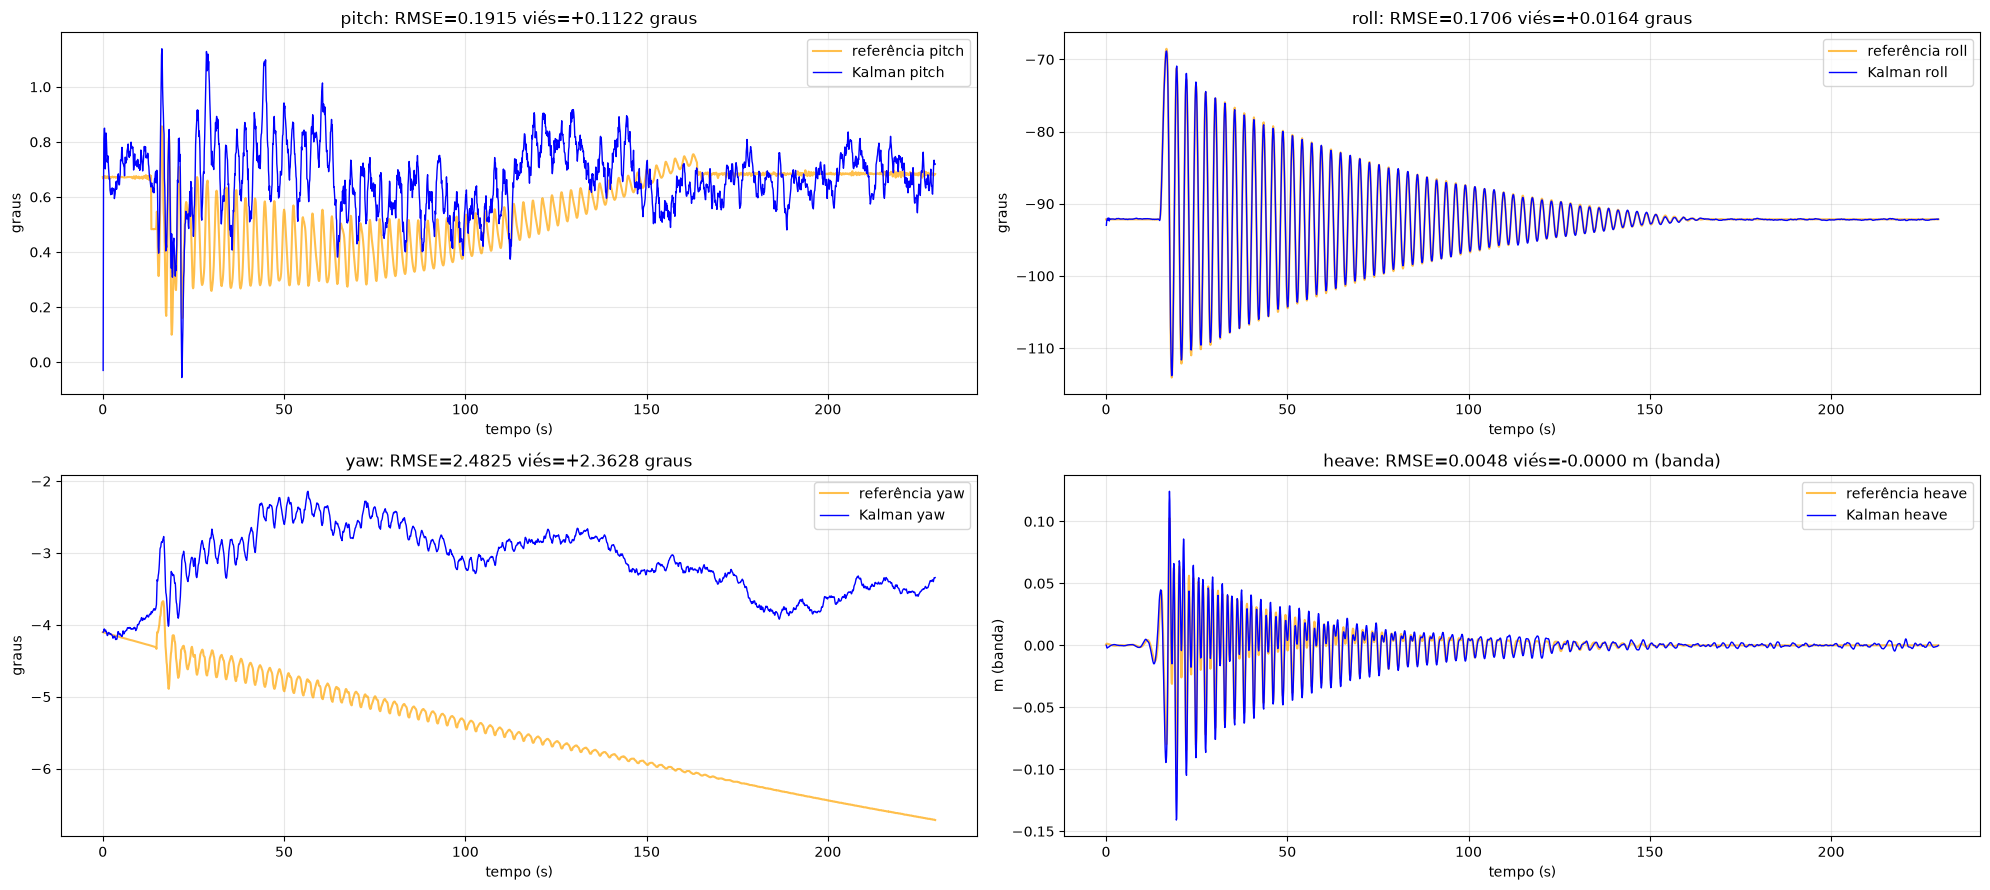

In [13]:
kf = KalmanFilter(df, xCols=SENSORS, yCols=LABELS, params={**FIXED, **best})
kf.update()
kf.plot()

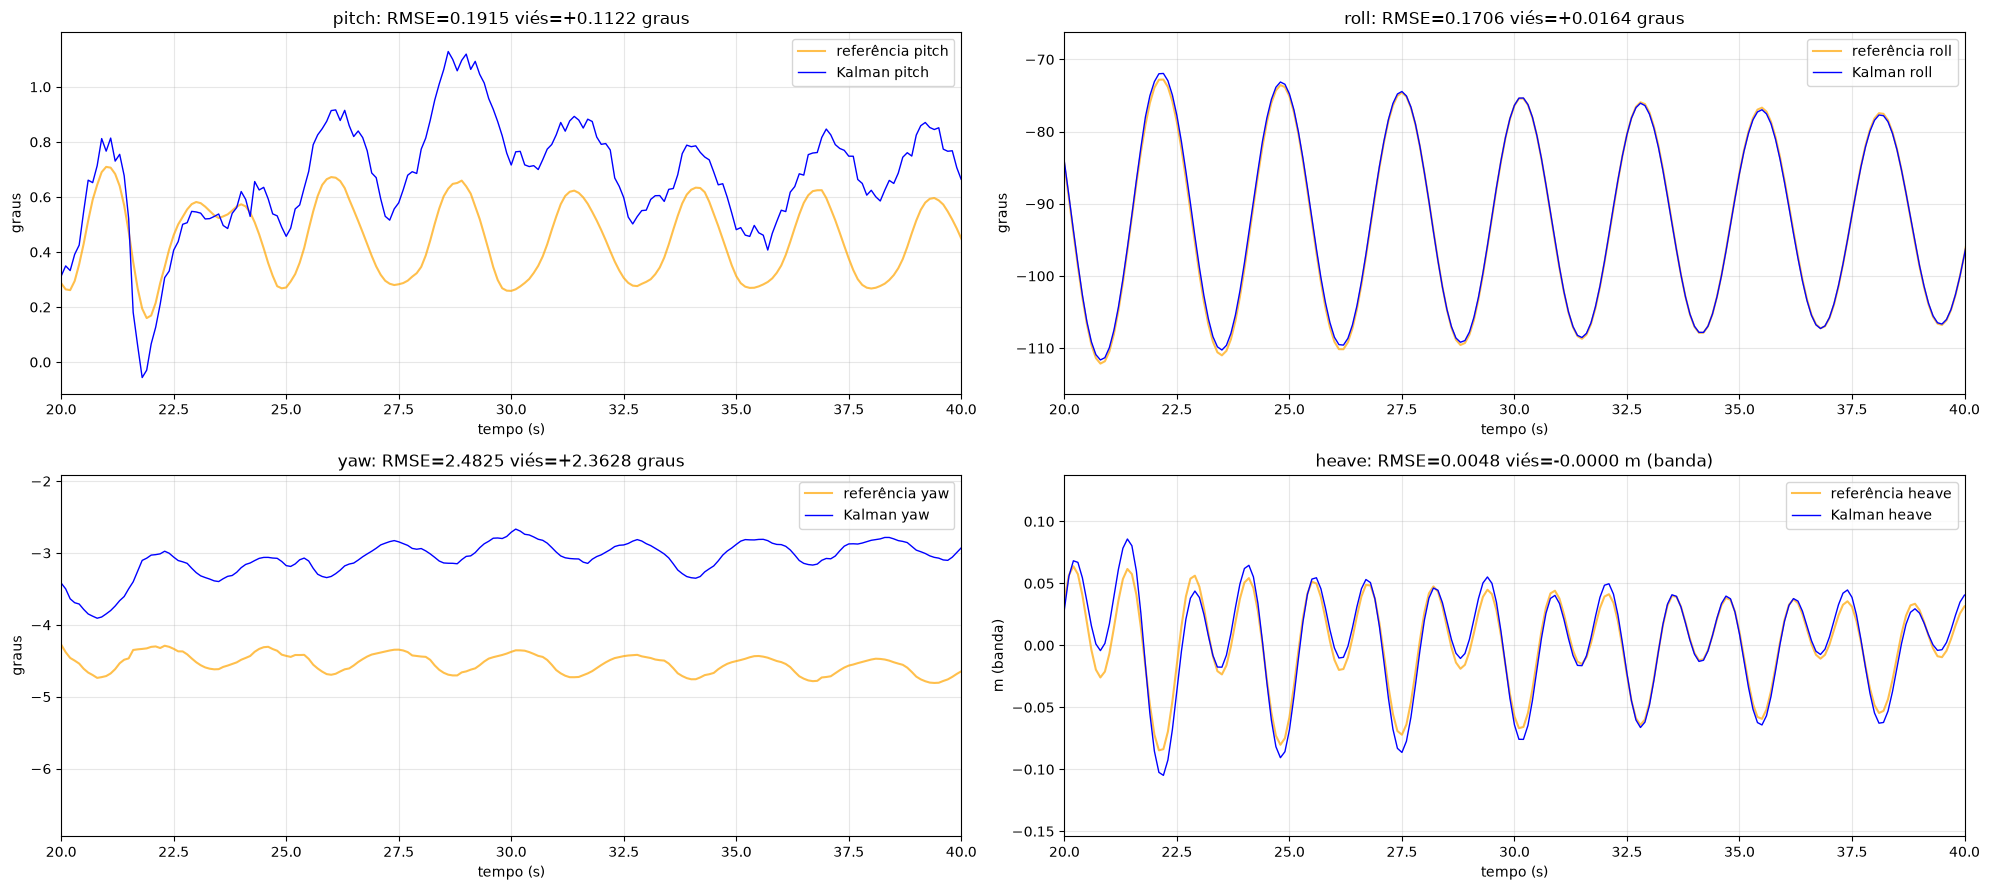

In [14]:
kf.plot(xlim=(20, 40))

# VALIDAÇÃO
- **Ajuste:** treino e teste, nivelamento fora da amostra e o AHRS interno do Kernel como base de comparação
- **Heave:** o que a referência de heave é, pela verdade cinemática e pela cadeia da EP identificada no próprio sinal da Seatex
- **Implementação:** jacobianas por diferenças finitas e resposta em frequência discreta do GP·HS contra a analítica
- **Saídas inerciais e consistência:** aceleração angular e aceleração no ponto contra a Seatex; NIS
- **Verdade conhecida:** navio sintético com heave no CG e gêmeo digital do ensaio, que projeta 10 Hz × 100 Hz e amostra instantânea × média
- **Generalização:** os outros ensaios brutos com os parâmetros desta busca, só a calibração refeita

### TREINO E TESTE
- O RMSE de cada janela e o objetivo da busca no treino e no teste, para o ponto de partida físico e para o ótimo: se o teste piorasse, a busca teria decorado o treino

In [15]:
windows = {'treino': TRAIN, 'teste': ~TRAIN, 'balanço': moving, 'repouso': static, 'tudo': np.ones(len(df), bool)}
metrics = {name: {k: v['rmse'] for k, v in kf.get(mask).items()} for name, mask in windows.items()}
table   = pd.DataFrame(metrics).T
table['heave'] *= 1000
search  = pd.DataFrame({'treino': [attitude(physical, TRAIN), attitude(best, TRAIN)], 'teste': [attitude(physical, ~TRAIN), attitude(best, ~TRAIN)]}, index=['ponto físico', 'busca'])
display(table.rename(columns={'heave': 'heave (mm)'}).round(4), search.round(4))

,pitch,roll,yaw,heave (mm)
treino,0.2326,0.2195,2.1314,6.5600
teste,0.1387,0.1002,2.7898,1.7641
balanço,0.2310,0.2028,2.4104,5.8392
repouso,0.0698,0.0786,2.6146,1.4349
tudo,0.1915,0.1706,2.4825,4.8034


,treino,teste
ponto físico,0.7644,0.4134
busca,0.4521,0.2390


#### NIVELAMENTO FORA DA AMOSTRA
- O mesmo filtro nivelado só com a primeira metade do repouso, avaliado na segunda: o nivelamento é uma constante da instalação, não um ajuste ao trecho

In [16]:
early = KalmanFilter(df, xCols=SENSORS, yCols=LABELS, params={**FIXED, **best, **dict(zip(['alignX', 'alignY', 'alignZ'], level(df[static & TRAIN], mount)))})
early.update()

pd.DataFrame({name: {k: kalman.get(static & ~TRAIN)[k]['rmse'] for k in ['roll', 'pitch']} for name, kalman in [('todo o repouso', kf), ('primeira metade', early)]}).T.round(4)

,roll,pitch
todo o repouso,0.0692,0.0594
primeira metade,0.0785,0.0595


### AHRS INTERNO DO KERNEL
- O Kernel tem um AHRS próprio: Euler do ICD, $C = R_z(-K)\,R_x(\theta)\,R_y(\phi)$ do corpo para ENU; a vertical dele nos eixos da referência dá roll e pitch comparáveis
- Ele não conhece o braço de alavanca: a 1,9 m do pivô, a aceleração centrípeta e a tangencial entram como se fossem gravidade

In [17]:
C    = Rotation.from_euler('ZXY', np.c_[-df.target_yaw, df.target_pitch, df.target_roll], degrees=True).as_matrix()
up   = C[:, 2, :] @ Rotation.from_euler('xyz', align, degrees=True).as_matrix()    # VERTICAL DO AHRS NOS EIXOS DA REFERÊNCIA
ahrs = {'roll': np.degrees(np.arctan2(-up[:, 1], -up[:, 2])), 'pitch': np.degrees(np.arctan2(up[:, 0], np.hypot(up[:, 1], up[:, 2])))}
cut  = [('balanço', moving), ('repouso', static)]

baseline = {
    'Kalman': {f'{name} {label}': np.sqrt(np.mean(kf.error(name, name)[mask]**2)) for name in ['roll', 'pitch'] for label, mask in cut},
    'AHRS do Kernel': {f'{name} {label}': np.sqrt(np.mean((ahrs[name] - df[name].to_numpy())[mask]**2)) for name in ['roll', 'pitch'] for label, mask in cut}
}

pd.DataFrame(baseline).T.round(4)

,roll balanço,roll repouso,pitch balanço,pitch repouso
Kalman,0.2028,NaN,0.231,NaN
AHRS do Kernel,1.9318,0.0367,0.222,0.009


### REFERÊNCIA DE HEAVE
- Ponto rígido a $m$ do pivô: deslocamento vertical $z(t) = [R(t)\,m]_z$, sem integração. Na banda do pêndulo a Seatex reproduz essa verdade com erro de milímetros; o `la_pos_mon_d` bruto, não
- A cadeia da EP aplicada à aceleração vertical da própria Seatex, $(R f)_z + g$, com $T_h$, $\varepsilon$, um resto de DC e o estado inicial por mínimos quadrados, nos dois modos da posição — GP ($p = y'$) e HS ($p = y' + 4\varepsilon\omega_c y$): se reproduz o `la_pos_mon_d` inteiro, os metros de excursão lenta são resposta do filtro dela, não movimento

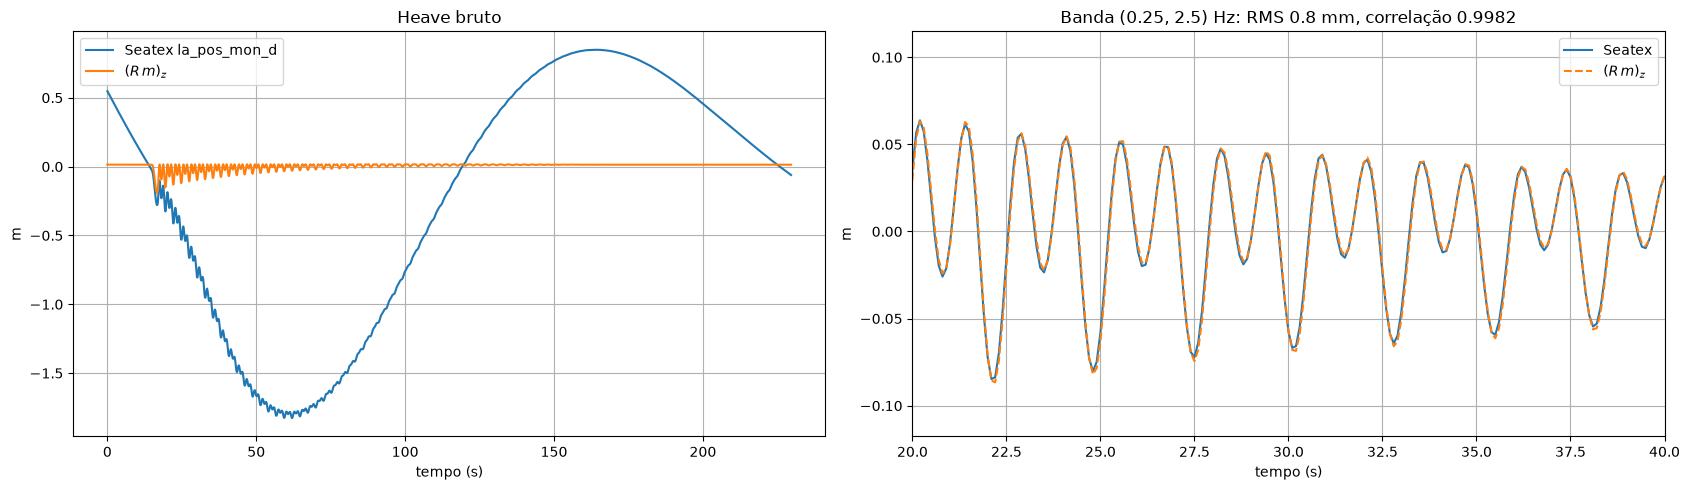

In [18]:
R         = Rotation.from_quat(df[['ref_q1', 'ref_q2', 'ref_q3', 'ref_q0']].to_numpy()).as_matrix()
window    = moving & (time > time[moving][0] + 20)
seatex    = kf.band(df.heave.to_numpy())
kinematic = kf.band((R @ point)[:, 2])    # DESLOCAMENTO VERTICAL DO PONTO DA SEATEX, SEM INTEGRAÇÃO NENHUMA
error     = (seatex - kinematic)[window]

plt.figure(figsize=(17, 5))
plt.subplot(1, 2, 1)
plt.plot(df.time, df.heave, label='Seatex la_pos_mon_d'); plt.plot(df.time, (R @ point)[:, 2] - (R @ point)[moving, 2].mean(), label='$(R\\,m)_z$')
plt.title('Heave bruto'); plt.xlabel('tempo (s)'); plt.ylabel('m'); plt.grid(); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(df.time, seatex, label='Seatex'); plt.plot(df.time, kinematic, '--', label='$(R\\,m)_z$'); plt.xlim(20, 40)
plt.title(f'Banda {KalmanFilter.HEAVE_BAND} Hz: RMS {1000*np.sqrt(np.mean(error**2)):.1f} mm, correlação {np.corrcoef(seatex[window], kinematic[window])[0, 1]:.4f}'); plt.xlabel('tempo (s)'); plt.ylabel('m'); plt.grid(); plt.legend()

plt.tight_layout()
plt.show()

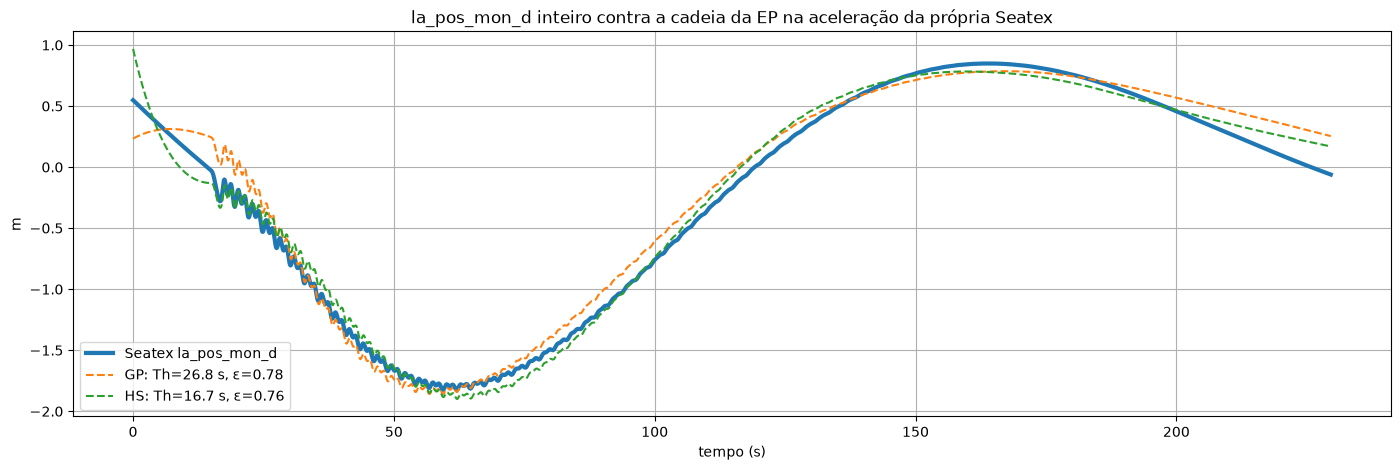

,Th (s),ε,DC (mm/s²),RMS (m)
GP,26.7754,0.7763,-0.6489,0.1299
HS,16.6920,0.7647,1.1152,0.0918


In [19]:
step     = np.diff(time, prepend=time[0])
vertical = np.einsum('nj,nj->n', R[:, 2, :], df[['ref_ax', 'ref_ay', 'ref_az']].to_numpy())    # (R f)_z: TERCEIRA LINHA DE R


# CADEIA DO MRU-5 NA ACELERAÇÃO VERTICAL DA SEATEX, PARTINDO DE UM ESTADO DADO; hs LIGA O MODO HS NA POSIÇÃO
def seatexHeave(p, hs):
    mru = KalmanFilter(df, xCols=SENSORS, yCols=LABELS, params={'heavePeriod': p[0], 'heaveDamping': p[1]})
    vel, pos, out = np.array(p[3:5]), np.array(p[5:7]), np.zeros(len(vertical))
    accel = vertical + gRef + p[2]

    for k in range(len(vertical)):
        v   = mru.section(vel, accel[k-1] if k else accel[0], accel[k], step[k])
        pos = mru.section(pos, vel[1], v[1], step[k])
        vel = v
        out[k] = pos[1] + (4*p[1]*mru.wc*pos[0] if hs else 0.0)

    return out


bounds = ([2, 0.2, -0.05, -50, -5, -50, -5], [40, 1.0, 0.05, 50, 5, 50, 5])
modes  = {}
plt.figure(figsize=(17, 5))
plt.plot(df.time, df.heave, label='Seatex la_pos_mon_d', linewidth=3)

for name, hs in [('GP', False), ('HS', True)]:
    fit         = least_squares(lambda p: seatexHeave(p, hs) - df.heave.to_numpy(), [15, 0.7, 0, 0, 0, 0, 0.6], bounds=bounds)
    chain       = seatexHeave(fit.x, hs)
    modes[name] = {'Th (s)': fit.x[0], 'ε': fit.x[1], 'DC (mm/s²)': 1000*fit.x[2], 'RMS (m)': np.sqrt(np.mean((chain - df.heave)**2))}
    plt.plot(df.time, chain, '--', label=f'{name}: Th={fit.x[0]:.1f} s, ε={fit.x[1]:.2f}')

plt.title('la_pos_mon_d inteiro contra a cadeia da EP na aceleração da própria Seatex'); plt.xlabel('tempo (s)'); plt.ylabel('m'); plt.grid(); plt.legend()
plt.show()
pd.DataFrame(modes).T.round(4)

### JACOBIANAS E DISCRETIZAÇÃO
- $H$: derivada de $h(q\otimes\delta q(\delta\theta)) = R(q\otimes\delta q)^\top[0,0,-1]$ por diferença central contra $[h\times]$
- $\Phi$: erro verdadeiro depois de um passo, propagando um estado perturbado em $\delta\theta$ e $\delta b$, contra $\Phi\,\delta x$
- GP·HS discreto: seno de aceleração na cadeia a 10 Hz e a 100 Hz, ganho e fase contra $G_{GP}G_{HS}(j\omega)$ analítico

In [20]:
test  = KalmanFilter(df, xCols=SENSORS, yCols=LABELS, params={**FIXED, **best})
q     = Rotation.random(random_state=1).as_quat()[[3, 0, 1, 2]]
h     = lambda q: -test.quatToDCM(q)[2]
dq    = lambda v: test.quatMul(q, test.quatFromRotVec(v))
numH  = np.array([(h(dq(e*1e-6)) - h(dq(-e*1e-6)))/2e-6 for e in np.eye(3)]).T
checks = {'H: [h x] contra diferença central': np.abs(numH - test.skew(h(q))).max()}

w, bias, theta = np.radians([20, -10, 35]), np.radians([0.05, -0.03, 0.02]), np.radians([0.004, -0.002, 0.003])
increment, F = test.transition(w, dt)
nominal = test.quatMul(q, increment)
real    = test.quatMul(dq(theta), test.quatFromRotVec((w - bias)*dt))    # O GIRO LÊ w; A TAXA VERDADEIRA É w - db
true    = Rotation.from_quat(test.quatMul(nominal*[1, -1, -1, -1], real)[[1, 2, 3, 0]]).as_rotvec()
checks['Φ: erro propagado contra Φ δx (relativo)'] = np.abs(true - (F @ np.r_[theta, bias])[:3]).max() / np.abs(true).max()


# GANHO E FASE DA POSIÇÃO DA CADEIA PARA UM SENO DE PERÍODO period AMOSTRADO A sample
def response(mru, period, sample, cycles=40):
    t     = np.arange(0, cycles*period, sample)
    chain = {'vel': np.zeros(2), 'pos': np.zeros(2), 'g': None}
    out   = np.array([mru.heave(chain, -(2*np.pi/period)**2*np.sin(2*np.pi*tk/period), 0.0, 0.0, sample if k else 0.0)[0] for k, tk in enumerate(t)])
    late  = t > cycles*period/2
    coef, *_ = np.linalg.lstsq(np.c_[np.sin(2*np.pi*t/period), np.cos(2*np.pi*t/period)][late], out[late], rcond=None)
    return np.hypot(*coef), np.degrees(np.arctan2(coef[1], coef[0]))


mru = KalmanFilter(df, xCols=SENSORS, yCols=LABELS, params={'heavePeriod': 10.0})
for period in [8.0, 12.0]:
    s  = 2j*np.pi/period
    d  = s**2 + 2*mru.heaveDamping*mru.wc*s + mru.wc**2
    Hs = (s**2/d) * (s**2 + 4*mru.heaveDamping*mru.wc*s)/d
    for sample in [0.1, 0.01]:
        gain, phase = response(mru, period, sample)
        checks[f'GP·HS {period:.0f} s a {1/sample:.0f} Hz: ganho, fase contra analítico'] = f'{gain/abs(Hs) - 1:+.2e}, {phase - np.degrees(np.angle(Hs)):+.3f}°'

pd.Series(checks, name='erro')

H: [h x] contra diferença central                                   0.0
Φ: erro propagado contra Φ δx (relativo)                       0.000111
GP·HS 8 s a 10 Hz: ganho, fase contra analítico      +4.67e-03, +0.015°
GP·HS 8 s a 100 Hz: ganho, fase contra analítico     -2.33e-03, -0.010°
GP·HS 12 s a 10 Hz: ganho, fase contra analítico     +8.45e-03, +0.038°
GP·HS 12 s a 100 Hz: ganho, fase contra analítico    +9.38e-04, +0.005°
Name: erro, dtype: object

### COMPONENTES INERCIAIS FILTRADAS
- Aceleração angular dos osciladores contra a diferença central do giro da Seatex, 20 vezes menos ruidoso, e contra a diferença finita do Kernel
- Aceleração no ponto da Seatex (Eq. 2) contra o acelerômetro da própria Seatex; o yaw das duas não é observável, então o horizontal vai pela norma

In [21]:
alphaRef  = np.gradient(df[['ref_wx', 'ref_wy', 'ref_wz']].to_numpy(), time, axis=0)
alphaFlt  = kf.result[['kalman_alpha_x', 'kalman_alpha_y', 'kalman_alpha_z']].to_numpy()
alphaDiff = np.r_[np.full((1, 3), np.nan), np.diff(kf.process(df[['wx', 'wy', 'wz']].to_numpy()), axis=0)/dt]
accelRef  = np.einsum('nij,nj->ni', R, df[['ref_ax', 'ref_ay', 'ref_az']].to_numpy()) + [0, 0, gRef]
accelFlt  = kf.result[['kalman_accel_n', 'kalman_accel_e', 'kalman_accel_d']].to_numpy()
rms       = lambda x: float(np.sqrt(np.nanmean(x[window]**2)))

inertial = {
    'α osciladores (graus/s²)': [rms(alphaFlt[:, k] - alphaRef[:, k]) for k in range(3)],
    'α diferença finita (graus/s²)': [rms(alphaDiff[:, k] - alphaRef[:, k]) for k in range(3)],
    'a no ponto (m/s²)': [rms(np.linalg.norm(accelFlt[:, :2], axis=1) - np.linalg.norm(accelRef[:, :2], axis=1)), np.nan, rms(accelFlt[:, 2] - accelRef[:, 2])]
}

pd.DataFrame(inertial, index=['x / horizontal', 'y', 'z / vertical']).T.round(4)

,x / horizontal,y,z / vertical
α osciladores (graus/s²),6.0867,0.7783,0.5724
α diferença finita (graus/s²),3.9298,3.1392,3.7473
a no ponto (m/s²),0.2134,NaN,0.0689


### CONSISTÊNCIA DO FILTRO
- NIS da correção do acelerômetro, $\epsilon = \nu^\top S^{-1}\nu$, segue uma $\chi^2_3$ de média 3 quando $R$ é o ruído verdadeiro (Bar-Shalom, Li e Kirubarajan 2001)
- Parado, $R$ é o ruído medido do sensor e a média deve ficar perto de 3; em movimento $R$ é o que a busca escolheu para cobrir erros de modelo correlacionados no tempo (braço de alavanca, instante da amostra), e média abaixo de 3 é filtro conservador ali

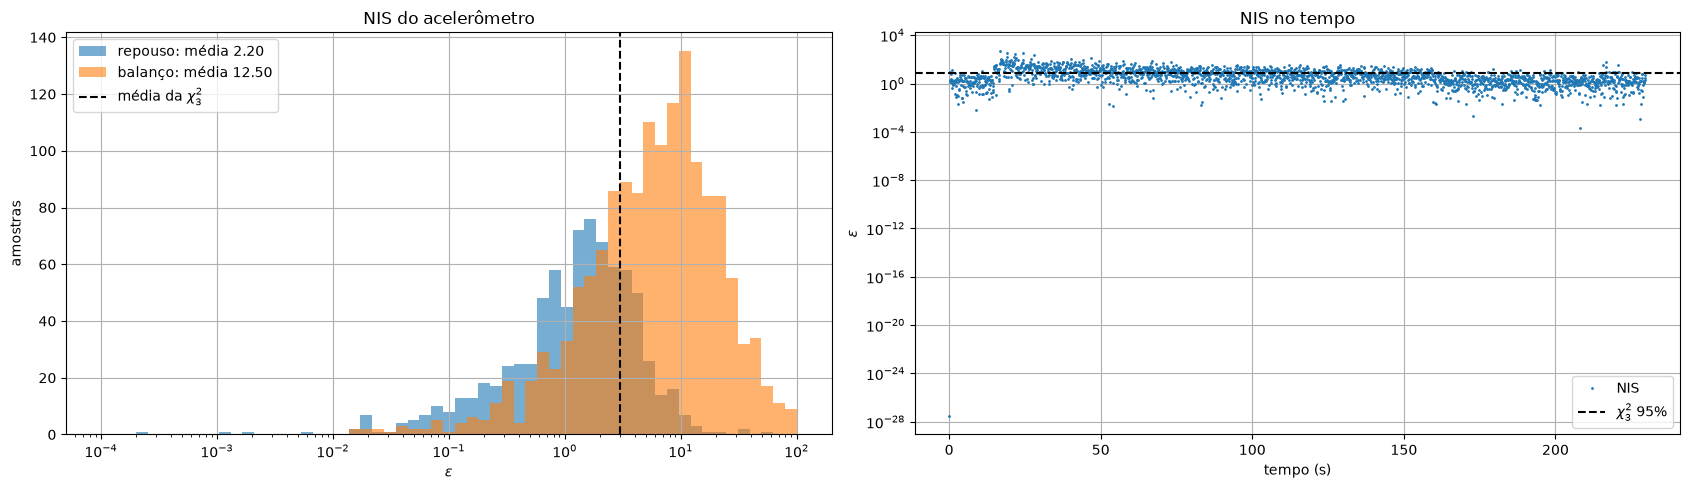

In [22]:
plt.figure(figsize=(17, 5))
plt.subplot(1, 2, 1)

for label, mask in [('repouso', static), ('balanço', moving)]:
    values = kf.nis[mask & np.isfinite(kf.nis)]
    plt.hist(values, bins=np.logspace(-4, 2, 60), alpha=.6, label=f'{label}: média {values.mean():.2f}')

plt.xscale('log'); plt.axvline(3, color='k', linestyle='--', label='média da $\\chi^2_3$')
plt.title('NIS do acelerômetro'); plt.xlabel('$\\epsilon$'); plt.ylabel('amostras'); plt.grid(); plt.legend()

plt.subplot(1, 2, 2)
plt.semilogy(kf.result.time, kf.nis, '.', ms=2, label='NIS')
plt.axhline(7.81, color='k', linestyle='--', label='$\\chi^2_3$ 95%')
plt.title('NIS no tempo'); plt.xlabel('tempo (s)'); plt.ylabel('$\\epsilon$'); plt.grid(); plt.legend()

plt.tight_layout()
plt.show()

### NAVIO SIMULADO
- Navio sintético: rolagem de 5° em 10 s mais 2° em 7 s, arfagem de 2° em 6 s, guinada lenta, heave do CG de 1 m em 8 s mais 0,5 m em 12 s e avanço e deriva menores
- IMU a $r = (2, 1, -3)$ m do CG e ponto de medida em $m = (10, 2, -5)$ m; giro e acelerômetro com o ruído por amostra do Kernel parado e bias de até 0,02 °/s, 10 Hz, $T_h$ = 10 s
- Aqui a cadeia do CG trabalha de verdade; ganho e fase a 8 s e 12 s devem ser os do $G_{GP}G_{HS}$ analítico

In [23]:
SIM_LEVER = np.array([2.0, 1.0, -3.0])     # m, IMU NO CORPO A PARTIR DO CG
SIM_POINT = np.array([10.0, 2.0, -5.0])    # m, PONTO DE MEDIDA NO CORPO A PARTIR DO CG
SIM_BIAS  = np.radians([0.02, -0.01, 0.015])


# NAVIO SINTÉTICO A 1 kHz, AMOSTRADO A dt COMO O ENSAIO
def simulate(duration, seed=7):
    rng   = np.random.default_rng(seed)
    fine  = np.arange(0, duration, 1e-3)
    wave  = lambda amplitude, period, phase=0: amplitude*np.sin(2*np.pi*fine/period + phase)
    euler = np.radians(np.c_[wave(5, 10) + wave(2, 7, 1), wave(2, 6, 0.5), 30 + wave(1, 40)])
    cg    = np.c_[wave(0.5, 9), wave(0.3, 11), wave(1.0, 8) + wave(0.5, 12, 2)]
    R     = Rotation.from_euler('xyz', euler).as_matrix()
    W     = np.einsum('nji,njk->nik', R, np.gradient(R, fine, axis=0))    # R^T dR/dt = [ω×]
    w     = np.c_[W[:, 2, 1], W[:, 0, 2], W[:, 1, 0]]
    alpha = np.gradient(w, fine, axis=0)
    accel = np.gradient(np.gradient(cg, fine, axis=0), fine, axis=0)
    force = np.einsum('nji,nj->ni', R, accel - [0, 0, G]) + np.cross(alpha, SIM_LEVER) + np.cross(w, np.cross(w, SIM_LEVER))
    k     = slice(0, len(fine), round(dt/1e-3))
    n     = len(fine[k])

    sim = pd.DataFrame({'time': fine[k]})
    sim[['ax', 'ay', 'az']] = force[k] + rng.normal(0, ACCEL_SIGMA, (n, 3))
    sim[['wx', 'wy', 'wz']] = np.degrees(w[k] + SIM_BIAS) + rng.normal(0, GYRO_SIGMA, (n, 3))
    sim[['roll', 'pitch', 'yaw']] = np.degrees(euler[k])
    sim['heave'] = cg[k, 2] + (R[k] @ SIM_POINT)[:, 2]
    sim['accel_n'], sim['accel_e'], sim['accel_d'] = (accel + np.einsum('nij,nj->ni', R, np.cross(alpha, SIM_POINT) + np.cross(w, np.cross(w, SIM_POINT))))[k].T
    return sim


sim    = simulate(900.0)
params = {**best, 'g': G, 'rateNoise': RATE_NOISE, 'zuptNoise': RATE_NOISE, 'stillNoise': STILL_NOISE, 'spike': SPIKE, 'heavePeriod': 10.0, 'yaw0': 30.0, **dict(zip(['leverX', 'leverY', 'leverZ', 'pointX', 'pointY', 'pointZ'], [*SIM_LEVER, *SIM_POINT]))}
ship   = KalmanFilter(sim, xCols=SENSORS, yCols=LABELS, params=params)
ship.update()

late  = (sim.time > 300).to_numpy()
heave = ship.result.kalman_heave.to_numpy()
true  = sim.heave.to_numpy() - sim.heave[late].mean()
cols  = ['kalman_accel_n', 'kalman_accel_e', 'kalman_accel_d']
b, a  = signal.butter(4, (0.05, 0.5), btype='band', fs=1/dt)


# GANHO E FASE DO HEAVE ESTIMADO CONTRA O VERDADEIRO NUM PERÍODO, POR MÍNIMOS QUADRADOS EM SENO E COSSENO
def harmonic(period):
    X   = np.c_[np.sin(2*np.pi*sim.time/period), np.cos(2*np.pi*sim.time/period), np.ones(len(sim))][late]
    est = np.linalg.lstsq(X, heave[late], rcond=None)[0]
    ref = np.linalg.lstsq(X, true[late], rcond=None)[0]
    s   = 2j*np.pi/period
    d   = s**2 + 2*ship.heaveDamping*ship.wc*s + ship.wc**2
    Hs  = (s**2/d) * (s**2 + 4*ship.heaveDamping*ship.wc*s)/d
    return np.round([np.hypot(*est[:2])/np.hypot(*ref[:2]), np.degrees(np.arctan2(est[1], est[0]) - np.arctan2(ref[1], ref[0])), abs(Hs), np.degrees(np.angle(Hs))], 4)


simulation = {
    **{f'{name} (graus)': np.sqrt(np.mean(ship.error(name, name)[late]**2)) for name in ['roll', 'pitch', 'yaw']},
    'heave banda inteira (m)': np.sqrt(np.mean((heave - true)[late]**2)),
    'heave 0,05-0,5 Hz (m)': np.sqrt(np.mean(signal.filtfilt(b, a, (heave - true)[1:])[late[1:]]**2)),
    'heave rate (m/s)': np.sqrt(np.mean((ship.result.kalman_heave_rate - np.gradient(sim.heave, dt))[late]**2)),
    'a no ponto n, e, d (m/s²)': np.sqrt(np.mean((ship.result[cols].to_numpy() - sim[['accel_n', 'accel_e', 'accel_d']].to_numpy())[late]**2, axis=0)).round(4),
    **{f'heave {period:.0f} s: ganho, fase (graus), ganho e fase do GP·HS': harmonic(period) for period in [8.0, 12.0]},
    'bias estimado contra o real (graus/s)': np.c_[ship.bias, np.degrees(SIM_BIAS)].round(4).tolist()
}

pd.Series(simulation, name='erro')

roll (graus)                                                                                       0.307977
pitch (graus)                                                                                      0.417621
yaw (graus)                                                                                      132.797123
heave banda inteira (m)                                                                            0.416989
heave 0,05-0,5 Hz (m)                                                                              0.078292
heave rate (m/s)                                                                                   0.053129
a no ponto n, e, d (m/s²)                                                            [2.3938, 2.39, 0.3256]
heave 8 s: ganho, fase (graus), ganho e fase do GP·HS                       [1.0312, 0.2535, 1.025, 0.2368]
heave 12 s: ganho, fase (graus), ganho e fase do GP·HS                     [1.0706, 0.9617, 1.0553, 0.7744]
bias estimado contra o real 

### GÊMEO DIGITAL: 10 Hz × 100 Hz
- A atitude da referência vira uma trajetória suave a 1 kHz (spline cúbica) e o Kernel ideal sai do modelo de corpo rígido com o braço calibrado; o ruído é branco, por amostra
- Quatro aquisições: 10 e 100 Hz, com a amostra instantânea deste ensaio (o $\sigma$ da taxa interna de 2 kHz) ou em média (`Average_Output_Data` do Kernel, $\sigma = \mathrm{ARW}\sqrt{f}$ e $\mathrm{VRW}\sqrt{f}$ do datasheet)
- Os parâmetros de ruído seguem cada aquisição, como no Allan: densidade $\sigma^2/f$ do giro, variância por amostra no ZARU e nos osciladores, $\sigma_f^2/g^2$ no acelerômetro parado; os de modelo são os desta busca
- O RMSE é tirado nas janelas de teste; a linha de 10 Hz instantâneo tem de reproduzir o ensaio real, que vem embaixo, para o gêmeo valer

In [24]:
fine   = np.arange(0, time[-1], 1e-3)
spline = CubicSpline(time, np.unwrap(Rotation.from_quat(df[['ref_q1', 'ref_q2', 'ref_q3', 'ref_q0']].to_numpy()).as_euler('xyz'), axis=0), axis=0)
twinR  = Rotation.from_euler('xyz', spline(fine)).as_matrix()
twinW  = np.einsum('nji,njk->nik', twinR, np.gradient(twinR, fine, axis=0))
omega  = np.c_[twinW[:, 2, 1], twinW[:, 0, 2], twinW[:, 1, 0]]
force  = np.einsum('nji,j->ni', twinR, [0, 0, -G]) + np.cross(omega, np.cross(omega, lever)) + np.cross(np.gradient(omega, fine, axis=0), lever)


# O ENSAIO REFEITO A rate Hz COM RUÍDO BRANCO POR AMOSTRA, NOS EIXOS DA REFERÊNCIA
def twin(rate, gyroSigma, accelSigma, seed=3):
    rng  = np.random.default_rng(seed)
    k    = slice(0, len(fine), round(1/rate/1e-3))
    n    = len(fine[k])
    data = pd.DataFrame({'time': fine[k], 'static': np.interp(fine[k], time, static) > 0.5})
    data[['ax', 'ay', 'az']] = force[k] + rng.normal(0, accelSigma, (n, 3))
    data[['wx', 'wy', 'wz']] = np.degrees(omega[k]) + rng.normal(0, gyroSigma, (n, 3))
    data[['roll', 'pitch', 'yaw']] = np.degrees(spline(fine[k]))
    data['heave'] = (twinR[k] @ point)[:, 2]

    variance = math.radians(gyroSigma)**2
    noise    = {'rateNoise': math.log10(variance), 'zuptNoise': math.log10(variance), 'gyroNoise': math.log10(variance/rate), 'stillNoise': math.log10((accelSigma/G)**2)}
    start    = clock.perf_counter()
    model    = KalmanFilter(data, xCols=SENSORS, yCols=LABELS, params={**FIXED, **best, **noise, 'alignX': 0.0, 'alignY': 0.0, 'alignZ': 0.0})
    model.update()

    test = np.interp(fine[k], time, ~TRAIN) > 0.5
    rest = data.static.to_numpy()
    rmse = lambda name, mask: float(np.sqrt(np.nanmean(model.error(name, name)[mask & test]**2)))
    return {'roll dinâmico': rmse('roll', ~rest), 'pitch dinâmico': rmse('pitch', ~rest), 'roll estático': rmse('roll', rest), 'pitch estático': rmse('pitch', rest), 'Python (s)': clock.perf_counter() - start}


SCENARIOS = {
    '10 Hz instantâneo': (10, GYRO_SIGMA, ACCEL_SIGMA),
    '10 Hz em média': (10, ARW*math.sqrt(10), VRW*math.sqrt(10)),
    '100 Hz instantâneo': (100, GYRO_SIGMA, ACCEL_SIGMA),
    '100 Hz em média': (100, ARW*math.sqrt(100), VRW*math.sqrt(100))
}

projection = pd.DataFrame({name: twin(*values) for name, values in SCENARIOS.items()}).T
measured   = {f'{name} {label}': kf.get(mask & ~TRAIN)[name]['rmse'] for label, mask in [('dinâmico', moving), ('estático', static)] for name in ['roll', 'pitch']}
projection.loc['ensaio real, 10 Hz instantâneo'] = measured
projection.round(4)

,roll dinâmico,pitch dinâmico,roll estático,pitch estático,Python (s)
10 Hz instantâneo,0.1027,0.0638,0.0586,0.0542,0.5804
10 Hz em média,0.0384,0.0184,0.0103,0.0059,0.5813
100 Hz instantâneo,0.0441,0.0235,0.0207,0.0152,5.8219
100 Hz em média,0.0266,0.0097,0.0075,0.0045,6.7689
"ensaio real, 10 Hz instantâneo",0.1132,0.1658,0.0692,0.0594,NaN


### ENSAIOS INDEPENDENTES
- Os ensaios brutos do `Format/files` (rolagem em $x$ e em $z$, sete sessões), carregados pelo mesmo `loadRecording` do `Dataset/Format.ipynb`
- Por ensaio só a calibração é refeita — defasagem, montagem, braço e nivelamento —, como a cada instalação; os parâmetros do filtro são os desta busca
- Dinâmico contra a atitude da Seatex depois dos 10 s iniciais do balanço, estático contra a gravidade dela; o heave contra a verdade cinemática no próprio Kernel, $(R\,r)_z$ na banda: nas sessões `rolling_x` o acelerômetro da Seatex sai girado em relação à atitude que ela informa, e o ponto do `la_pos_mon_d` deixa de coincidir com o braço calibrado
- Ensaio cujo corpo rígido não fecha (resíduo da calibração acima de 0,5 m/s²) fica fora das médias

In [25]:
from Dataset.Recording.index import loadRecording

In [26]:
rows = []

for path in sorted(p for p in glob.glob(f'{RAW}/test*/rolling_*') if os.path.exists(f'{p}/reference/data.csv')):
    rec    = loadRecording(path).rename(columns={f'target_{var}': var for var in SENSORS} | {f'ref_{var}': var for var in LABELS})
    lag    = phaser.get(rec)
    rec    = phaser.set(rec, lag)
    rest   = rec.static.to_numpy()
    g      = float(np.linalg.norm(rec.loc[rest, ['ax', 'ay', 'az']], axis=1).mean())
    turn, arm, fit = calibrate(rec[~rest], ['ax', 'ay', 'az'], ['wx', 'wy', 'wz'], g)
    pose   = level(rec[rest], turn)
    ground = gravity(rec)

    for name in ['roll', 'pitch']:
        rec[name] = np.where(rest, ground[name], rec[name])

    rec['heave'] = (Rotation.from_quat(rec[['ref_q1', 'ref_q2', 'ref_q3', 'ref_q0']].to_numpy()).as_matrix() @ arm)[:, 2]    # VERDADE CINEMÁTICA NO PRÓPRIO KERNEL
    params = {**FIXED, **best, 'g': g, **dict(zip(['alignX', 'alignY', 'alignZ', 'leverX', 'leverY', 'leverZ', 'pointX', 'pointY', 'pointZ'], [*pose, *arm, *arm]))}
    kr     = KalmanFilter(rec, xCols=SENSORS, yCols=LABELS, params=params)
    kr.update()

    moved   = ~rest & (rec.time > rec.time[~rest].min() + 10).to_numpy()
    dynamic = kr.get(moved)
    resting = kr.get(rest)
    rows.append({'ensaio': os.path.relpath(path, RAW), 'defasagem (ms)': 1000*lag, 'resíduo (m/s²)': fit, 'roll dinâmico': dynamic['roll']['rmse'], 'pitch dinâmico': dynamic['pitch']['rmse'], 'roll estático': resting['roll']['rmse'], 'pitch estático': resting['pitch']['rmse'], 'heave (mm)': 1000*dynamic['heave']['rmse'], 'heave verdadeiro (mm)': 1000*np.nanstd(kr.band(rec.heave.to_numpy())[moved]), 'corr heave': dynamic['heave']['corr']})

independent = pd.DataFrame(rows)
summary     = independent[independent['resíduo (m/s²)'] < 0.5].groupby(independent.ensaio.str.split('/').str[1]).mean(numeric_only=True)
display(independent.round(3), summary.round(3))

,ensaio,defasagem (ms),resíduo (m/s²),roll dinâmico,pitch dinâmico,roll estático,pitch estático,heave (mm),heave verdadeiro (mm),corr heave
0,test1/rolling_x,9144.872,1.516,3.207,4.175,0.167,0.127,18.657,27.346,0.798
1,test1/rolling_z,17.679,0.084,0.168,0.236,0.079,0.070,4.242,18.235,0.981
2,test2/rolling_x,27.310,0.104,0.192,6.562,0.055,0.058,5.352,13.465,0.973
3,test2/rolling_z,19.657,0.070,0.148,0.408,0.066,0.069,3.710,15.909,0.979
4,test3/rolling_x,44.136,0.269,0.233,2.885,0.058,0.078,4.917,23.490,0.979
5,test3/rolling_z,22.785,0.066,0.122,1.005,0.058,0.069,3.086,10.420,0.971
6,test4/rolling_x,44.224,0.143,0.759,6.577,0.059,0.092,14.508,6.125,-0.901
7,test4/rolling_z,2697.673,1.516,0.339,0.253,0.147,0.088,25.938,28.615,0.619
8,test5/rolling_x,29.859,0.253,1.100,9.333,0.061,0.066,20.708,7.647,-0.952
9,test5/rolling_z,-5.211,0.160,0.278,0.355,0.065,0.064,6.642,31.664,0.979


,defasagem (ms),resíduo (m/s²),roll dinâmico,pitch dinâmico,roll estático,pitch estático,heave (mm),heave verdadeiro (mm),corr heave
ensaio,,,,,,,,,
rolling_x,36.382,0.192,0.571,6.339,0.058,0.073,11.371,12.682,0.025
rolling_z,7.617,0.105,0.198,0.449,0.093,0.081,4.580,17.969,0.972


# SALVANDO O MODELO
- `Backup/model_N/info.json`: parâmetros, calibração, métricas, projeção e ensaios independentes, para refazer o filtro
- `Dataset/results/`: o contrato do `Calibration` que o `Analysis.ipynb` lê — `model.csv` (ângulos e heave com o `_ref` da série inteira; o heave só na banda do movimento, a única onde a referência vale) e `filtered.csv` (sensores crus e entregues nos eixos da referência), cada um com o json de quem rodou

In [27]:
os.makedirs('Backup', exist_ok=True)
saved  = [name for name in os.listdir('Backup') if name.startswith('model_')]
output = f'Backup/model_{len(saved) + 1}'
os.makedirs(output, exist_ok=True)

results = {
    **model.getBest(),
    'fixed': FIXED,
    'search': {**SEARCH, 'seed': problem['seed'], 'bounds': {k: v['bounds'] for k, v in problem['variables'].items()}},
    'calibration': {'delay': delay, 'mount': mount.tolist(), 'align': align.tolist(), 'lever': lever.tolist(), 'point': point.tolist(), 'residual': fitKernel},
    'metrics': kf.get(),
    'windows': metrics,
    'projection': projection.to_dict(orient='index'),
    'independent': summary.to_dict(orient='index'),
    'bias': kf.bias.round(6).tolist(),
    'dataset': {'path': DATASET, 'samples': len(df), 'dt': dt}
}

pd.Series(results).to_json(f'{output}/info.json', indent=4)
print(output)
results

Backup/model_4


{'algorithm': 'genetic',
 'f': 0.4520618978167128,
 'runs': 1,
 'stopped': 39,
 'variables': {'gyroNoise': -6.4495489780253425,
  'biasNoise': -12.114521304409676,
  'accelNoise': -4.313550946053573,
  'accelGateK': -0.1985947236471547,
  'gyroPhase': 0.49745694095314436},
 'fixed': {'g': 9.787577758879639,
  'rateNoise': -4.795930383948624,
  'zuptNoise': -4.795930383948624,
  'stillNoise': -5.259707038333712,
  'spike': 2.0,
  'heavePeriod': np.float64(1.3),
  'alignX': np.float64(90.52922211313371),
  'alignY': np.float64(0.36914598526831666),
  'alignZ': np.float64(7.544073086094893),
  'leverX': np.float64(0.04180594986886308),
  'leverY': np.float64(-1.9102454204189605),
  'leverZ': np.float64(0.0592869391484202),
  'pointX': np.float64(0.06779311089390352),
  'pointY': np.float64(-1.9747174817715103),
  'pointZ': np.float64(-0.1718941505448587)},
 'search': {'population': 30,
  'generations': 40,
  'workers': 8,
  'backend': 'process',
  'seed': 42,
  'bounds': {'gyroNoise': (-9

In [28]:
RESULTS = 'Dataset/results'
os.makedirs(RESULTS, exist_ok=True)

series = df[['time', 'static']].copy()

for name in ANGLES:
    series[name]          = kf.result[f'kalman_{name}']
    series[f'{name}_ref'] = df[name]

series['heave']     = kf.band(kf.result.kalman_heave)
series['heave_ref'] = kf.band(df.heave)

sensors = df[['time', 'static']].copy()
sensors[['ax_raw', 'ay_raw', 'az_raw']] = kf.process(df[['ax', 'ay', 'az']].to_numpy())
sensors[['wx_raw', 'wy_raw', 'wz_raw']] = kf.process(df[['wx', 'wy', 'wz']].to_numpy())
sensors[['ax', 'ay', 'az']]             = sensors[['ax_raw', 'ay_raw', 'az_raw']].to_numpy()    # O ACELERÔMETRO ENTRA NO FILTRO COMO MEDIDA, SEM FILTRAGEM
sensors[['wx', 'wy', 'wz']]             = kf.result[['kalman_wx', 'kalman_wy', 'kalman_wz']].to_numpy()

record  = {'strategy': 'kalman_fusion', 'backup': output, 'targets': LABELS, 'band': list(KalmanFilter.HEAVE_BAND), 'metrics': kf.get()}
filters = {'strategy': 'kalman_fusion', 'backup': output, 'filters': {axis: {'name': 'oscilador harmônico' if axis[0] == 'w' else 'nenhum'} for axis in SENSORS}}

series.dropna().to_csv(f'{RESULTS}/model.csv', index=False)
sensors.dropna().to_csv(f'{RESULTS}/filtered.csv', index=False)
pd.Series(record).to_json(f'{RESULTS}/model.json', indent=4)
pd.Series(filters).to_json(f'{RESULTS}/filters.json', indent=4)
display(series.dropna().head(3), sensors.dropna().head(3))

,time,static,pitch,pitch_ref,roll,roll_ref,yaw,yaw_ref,heave,heave_ref
1,0.1,True,-0.030285,0.666922,-92.978779,-92.162745,-4.101805,-4.102748,-0.000015,0.001143
2,0.2,True,0.625429,0.670996,-92.333923,-92.162596,-4.097300,-4.104366,-0.001511,0.001376
3,0.3,True,0.811895,0.670297,-92.215741,-92.159234,-4.071980,-4.106085,-0.002194,0.001321


,time,static,ax_raw,ay_raw,az_raw,wx_raw,wy_raw,wz_raw,ax,ay,az,wx,wy,wz
1,0.1,True,0.142869,9.762995,0.399690,0.244135,0.307800,0.368940,0.142869,9.762995,0.399690,0.244132,0.307796,0.368934
2,0.2,True,0.132206,9.744484,0.359872,0.055268,-0.353252,0.152003,0.132206,9.744484,0.359872,0.182242,-0.359689,0.278762
3,0.3,True,0.136377,9.780714,0.380598,-0.054823,-0.130523,-0.017535,0.136377,9.780714,0.380598,0.130941,-0.141393,0.201982


# EXPORTANDO PARA O HARDWARE
- `Hardware/index.h` é o `KalmanFilter` em C++ com o contrato dos modelos do firmware (`setup(dt)`, `update(sensors, angles, dt)`, `reset()`, `toString()`), e este `config.h` leva os parâmetros que acabaram de rodar, já em unidade física
- O modelo recebe o que o Kernel entrega no modo HR: aceleração em **g** (multiplicada por `KALMAN_G0` lá dentro) e taxa em graus/s, nos eixos crus; `KALMAN_REAL` escolhe `float` no ESP32 e `double` no teste do computador
- `KALMAN_HEADING` em `NAN` pega a proa do próprio Kernel na primeira amostra; `align`, `lever` e `point` são da instalação do ensaio e mudam a cada instalação

In [29]:
STAMP = f'{datetime.date.today():%d/%m/%Y}'
value = lambda x: f'{x:.17g}'
array = lambda v: ', '.join(value(x) for x in v)

header = f'''#ifndef KALMAN_CONFIG_H
#define KALMAN_CONFIG_H

// GERADO POR KalmanFusion/1 - Model.ipynb EM {STAMP} ({output})
#define KALMAN_NAME          "kalman_fusion"
#define KALMAN_G0            {value(G0)}    // m/s^2 por g: o modo HR do Kernel entrega aceleracao em g
#define KALMAN_GRAVITY       {value(kf.g)}    // m/s^2, gravidade local, centro do gate e do detector de repouso
#define KALMAN_GYRO_NOISE    {value(kf.gyroNoise)}    // (rad/s)^2/Hz do ARW do giro
#define KALMAN_BIAS_NOISE    {value(kf.biasNoise)}    // (rad/s^2)^2/Hz do random walk do bias
#define KALMAN_ACCEL_NOISE   {value(kf.accelNoise)}    // variancia do versor do acelerometro em movimento
#define KALMAN_STILL_NOISE   {value(kf.stillNoise)}    // variancia do versor do acelerometro parado: o ruido do sensor
#define KALMAN_ZUPT_NOISE    {value(kf.zuptNoise)}    // (rad/s)^2 do ZARU
#define KALMAN_ACCEL_GATE    {value(kf.accelGateK)}    // ganho que infla R quando |a| foge de g
#define KALMAN_RATE_NOISE    {value(kf.rateNoise)}    // (rad/s)^2 da taxa medida nos osciladores
#define KALMAN_GYRO_PHASE    {value(kf.gyroPhase)}    // fase da taxa integrada: 0 retangular, 0.5 trapezoidal
#define KALMAN_SPIKE         {value(kf.spike)}    // m/s^2, salto isolado da aceleracao do CG que e pico
#define KALMAN_HEAVE_PERIOD  {value(kf.heavePeriod)}    // s, Th da EP 2 092 402: wc = 2 pi / (10 Th)
#define KALMAN_HEAVE_DAMPING {value(kf.heaveDamping)}    // eps dos filtros GP e HS
#define KALMAN_ALIGN_X       {value(kf.align[0])}    // graus, eixos crus do Kernel -> referencial do navio (Euler xyz)
#define KALMAN_ALIGN_Y       {value(kf.align[1])}
#define KALMAN_ALIGN_Z       {value(kf.align[2])}
#define KALMAN_HEADING       NAN    // proa inicial em graus; NAN pega a do Kernel

static const double KALMAN_LEVER[3] = {{{array(kf.lever)}}};    // m, do centro de rotacao (CG) ate o Kernel, no corpo
static const double KALMAN_POINT[3] = {{{array(kf.point)}}};    // m, do CG ate o ponto de medida do heave, no corpo

#endif
'''

open('Hardware/config.h', 'w').write(header)
print(header)

#ifndef KALMAN_CONFIG_H
#define KALMAN_CONFIG_H

// GERADO POR KalmanFusion/1 - Model.ipynb EM 08/10/2026 (Backup/model_4)
#define KALMAN_NAME          "kalman_fusion"
#define KALMAN_G0            9.8066499999999994    // m/s^2 por g: o modo HR do Kernel entrega aceleracao em g
#define KALMAN_GRAVITY       9.7875777588796389    // m/s^2, gravidade local, centro do gate e do detector de repouso
#define KALMAN_GYRO_NOISE    3.551820601863024e-07    // (rad/s)^2/Hz do ARW do giro
#define KALMAN_BIAS_NOISE    7.6820777015673699e-13    // (rad/s^2)^2/Hz do random walk do bias
#define KALMAN_ACCEL_NOISE   4.8579054066101561e-05    // variancia do versor do acelerometro em movimento
#define KALMAN_STILL_NOISE   5.4991170224700996e-06    // variancia do versor do acelerometro parado: o ruido do sensor
#define KALMAN_ZUPT_NOISE    1.5998144533309354e-05    // (rad/s)^2 do ZARU
#define KALMAN_ACCEL_GATE    0.6330022829950519    // ganho que infla R quando |a| foge de g
#define KALMAN_RATE_NOISE 

# VALIDAÇÃO DO C++
- `Hardware/Test/index.cpp` lê uma tabela, roda o `KalmanModel` amostra a amostra, grava as 18 saídas e mede o tempo médio do `update()`; `Hardware/Test/Arduino.h` é só o `String` que o modelo usa
- Compilado duas vezes: em `double` a diferença para o Python é a do arredondamento da máquina (mesmo algoritmo); em `float` é a precisão real do ESP32
- O Python roda sem olhar a coluna `static`, como o firmware: o repouso sai do detector nos dois

In [30]:
build = 'Hardware/Test/build'
data  = pd.DataFrame({'time': df.time, **{k: df[k]/G0 for k in ['ax', 'ay', 'az']}, **{k: df[k] for k in ['wx', 'wy', 'wz', 'pitch', 'roll', 'yaw']}})
units = {name: (np.degrees if name.startswith(('w', 'alpha')) else (lambda x: x)) for name in KalmanFilter.OUTPUTS}    # O C++ DEVOLVE TAXA E ACELERAÇÃO ANGULAR EM rad

os.makedirs(build, exist_ok=True)
data.to_csv(f'{build}/input.csv', index=False, float_format='%.17g')
comparison, timing = {}, {}

for real in ['double', 'float']:
    binary = f'{build}/kalman_{real}'
    subprocess.run(['g++', '-O2', '-std=c++17', '-Wall', '-Wextra', f'-DKALMAN_REAL={real}', '-I', 'Hardware/Test', '-I', 'Hardware', 'Hardware/Test/index.cpp', '-o', binary], check=True)
    run = subprocess.run([binary, f'{build}/input.csv', f'{build}/output_{real}.csv', f'{dt:.17g}'], check=True, capture_output=True, text=True)
    cpp = pd.read_csv(f'{build}/output_{real}.csv')
    comparison[real] = {name: np.nanmax(np.abs(kf.result[f'kalman_{name}'].to_numpy()[1:] - units[name](cpp[name].to_numpy()[1:]))) for name in KalmanFilter.OUTPUTS}
    timing[real]     = float(run.stdout)

print(f'update() no computador: {timing["double"]:.1f} µs em double e {timing["float"]:.1f} µs em float por amostra')
pd.DataFrame(comparison).rename_axis('máximo |Python - C++|')

update() no computador: 0.8 µs em double e 0.8 µs em float por amostra


,double,float
máximo |Python - C++|,,
roll,7.105427e-14,0.000084
pitch,5.107026e-15,0.000004
yaw,6.794565e-14,0.000375
heave,1.013772e-14,0.000033
heave_rate,5.134781e-15,0.000013
heave_accel,9.103829e-15,0.000021
wx,2.131628e-14,0.000014
wy,6.744605e-15,0.000006
wz,6.994405e-15,0.000002
